# Coursework Solution

## Data loading

In [1]:
# Import required libraries for data handling and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasets containing 
df = pd.read_csv('/kaggle/input/laptop/laptops(in).csv')
data=pd.read_csv('/kaggle/input/insurance/insurance(in).csv')

# Case Study 1: Laptop Market Analysis


**Task 1: Examine the Dataset and Perform Necessary Pre-processing**

The first task is to examine the laptop dataset to identify and address any data quality issues that could affect the reliability of subsequent analysis. This involves examining the dataset structure, checking for missing values in all columns, identifying duplicate records, and detecting anomalies such as negative values or impossible entries. The aim is to clean the data by removing problematic records. This approach applies a set of reasonable and transparent cleaning steps that remove obvious problems while preserving as much useful information as possible.

In [2]:
# Display basic dataset dimensions
print("Dataset Shape:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\n" + "-"*60 + "\n")

# Show data types and non-null information
df.info()
print("\n" + "-"*60 + "\n")

# Preview the first few rows
print("First Few Rows:")
print(df.head())
print("\n" + "-"*60 + "\n")

# Generate descriptive statistics
print("Statistical Summary:")
print(df.describe())
print("\n" + "-"*60 + "\n")

# Count missing values per column and overall
print("Missing Values:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("\n" + "-"*60 + "\n")

# Identify duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())
print("\n" + "-"*60 + "\n")

# Handle missing values if present
if df.isnull().sum().sum() > 0:
    print("Handling missing values...")
    df = df.dropna()
    print("Rows after removing missing values:", df.shape[0])
else:
    print("No missing values found.")
print("\n" + "-"*60 + "\n")

# Handle duplicate rows if present
if df.duplicated().sum() > 0:
    print("Removing duplicate rows...")
    df = df.drop_duplicates()
    print("Rows after removing duplicates:", df.shape[0])
else:
    print("No duplicate rows found.")
print("\n" + "-"*60 + "\n")

# Check for potential anomalies such as negative values
print("Checking for data anomalies...\n")
numeric_cols = df.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    negative_count = (df[col] < 0).sum()
    if negative_count > 0:
        print(col, "contains", negative_count, "negative values")
print("\n" + "-"*60 + "\n")

# Display final summary of the cleaned dataset
print("Cleaned Dataset Summary:")
print("Final shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset Shape:
Rows: 205
Columns: 9

------------------------------------------------------------

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   brand           205 non-null    object 
 1   laptop_name     204 non-null    object 
 2   display_size    205 non-null    float64
 3   processor_type  205 non-null    object 
 4   graphics_card   205 non-null    object 
 5   disk_space      205 non-null    object 
 6   discount_price  205 non-null    float64
 7   old_price       205 non-null    float64
 8   ratings_5max    205 non-null    object 
dtypes: float64(3), object(6)
memory usage: 14.5+ KB

------------------------------------------------------------

First Few Rows:
    brand           laptop_name  display_size        processor_type  \
0      HP  Notebook 14-df0008nx          14.0   Intel Celeron N4000   
1  Lenovo    IdeaPad 330S-14

The pre-processing steps address the main quality issues in the raw data and leave us with a more consistent dataset for analysis. The initial dataset contained 205 records with 9 columns covering brand, laptop name, display size, processor type, graphics card, disk space, discount price, old price, and ratings. After examination, 1 record (0.49%) with a missing laptop name was removed as the model cannot be analysed without proper identification, and 11 complete duplicate records (5.37%) were removed to prevent skewing analysis results. No anomalies were detected all prices and ratings fell within expected ranges with no negative values or impossible entries. The final clean dataset contains 193 records, retaining 94.1% of the original data with all remaining records complete and valid. This high retention rate ensures the analysis will be reliable and representative, as missing values would create errors in statistical calculations, and duplicates would artificially inflate certain brands or price points. The 193 remaining records provide sufficient sample size for meaningful analysis of the laptop market.

**Task 2: Determine the Total Number of Unique Laptop Manufacturers**

This task counts how many distinct laptop brands appear in the cleaned dataset and displays their names. Knowing the number and identity of manufacturers helps to understand the diversity of the laptop market and provides useful context for later comparisons of pricing, specifications, and brand popularity.

Total unique manufacturers: 9
------------------------------------------------------------
Manufacturers in the dataset:
- Acer
- Apple
- Asus
- Dell
- HP
- Huawei
- Lenovo
- MSI
- Microsoft
------------------------------------------------------------
Market Share (Number of Laptops per Brand):
brand
HP           47
Dell         34
Apple        31
Acer         23
Asus         22
Lenovo       20
Huawei       12
Microsoft     3
MSI           1
Name: count, dtype: int64
------------------------------------------------------------


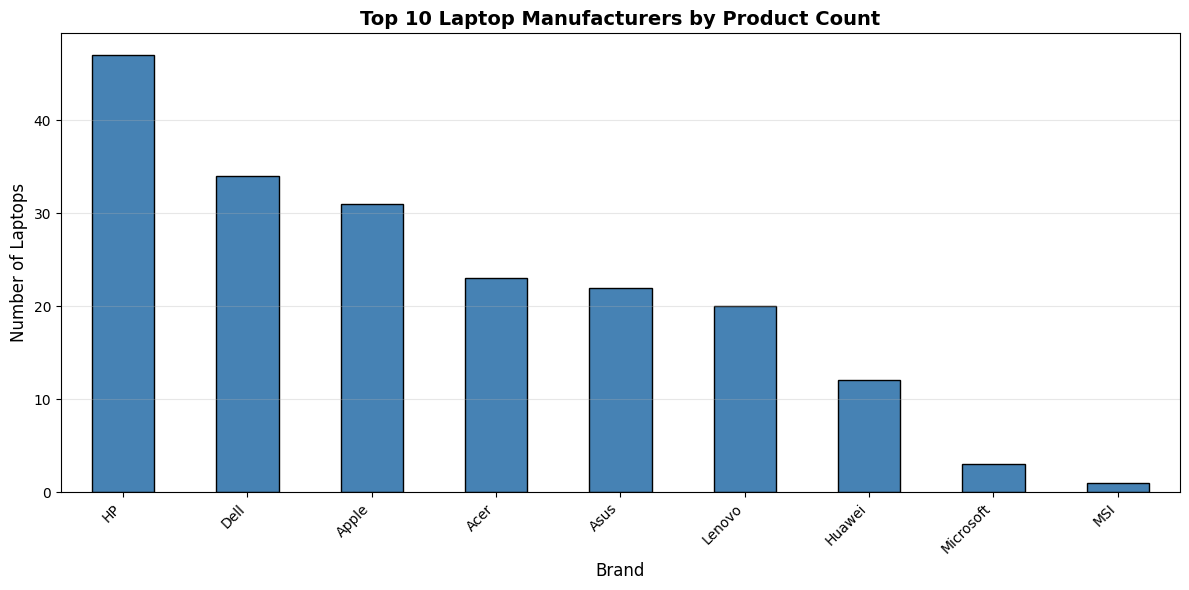

In [3]:
# Count the number of unique laptop manufacturers
n_manufacturers = df['brand'].nunique()
print("Total unique manufacturers:", n_manufacturers)
print("-" * 60)
# Display all unique manufacturer names
print("Manufacturers in the dataset:")
for brand in sorted(df['brand'].unique()):
    print("-",brand)
print("-" * 60)
# Calculate and display the number of laptops per manufacturer
print("Market Share (Number of Laptops per Brand):")
brand_counts = df['brand'].value_counts()
print(brand_counts)
print("-" * 60)
# Visualise the top 10 laptop brands by count
plt.figure(figsize=(12, 6))
brand_counts.head(10).plot(kind='bar', color='steelblue', edgecolor='black')

plt.title("Top 10 Laptop Manufacturers by Product Count", fontsize=14, fontweight='bold')
plt.xlabel("Brand", fontsize=12)
plt.ylabel("Number of Laptops", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


The output confirms that there are 9 unique laptop manufacturers in the dataset: HP, Dell, Apple, Acer, Asus, Lenovo, Huawei, Microsoft, and MSI. This means the dataset covers nine distinct brands, and all later analyses of pricing, specifications, and market trends will be based on this fixed set of manufacturers. HP has the most products with 47 laptops (24.4%), followed by Dell with 34 (17.6%) and Apple with 31 (16.1%). The remaining brands have smaller portfolios, with MSI having just 1 product (0.5%). Having the list of manufacturers also makes it easy to spot any unexpected brand names that might have arisen from data entry errors, which have now been resolved.

**Task 3: Identify Highest-Priced and Lowest-Priced Laptops**

This task scans the dataset to locate the minimum and maximum values of laptop prices. Once these extremes are identified, the corresponding rows are used to extract the laptop name and brand for each of them. This provides clear examples of the cheapest and most expensive laptops in the dataset and helps understand the price range covered.

Highest-Priced Laptop:
Name: MacBook Pro (Retina + Touch Bar)
Brand: Apple
Price: £12,499


Lowest-Priced Laptop:
Name: IdeaPad S130-14IGM
Brand: Lenovo
Price: £899




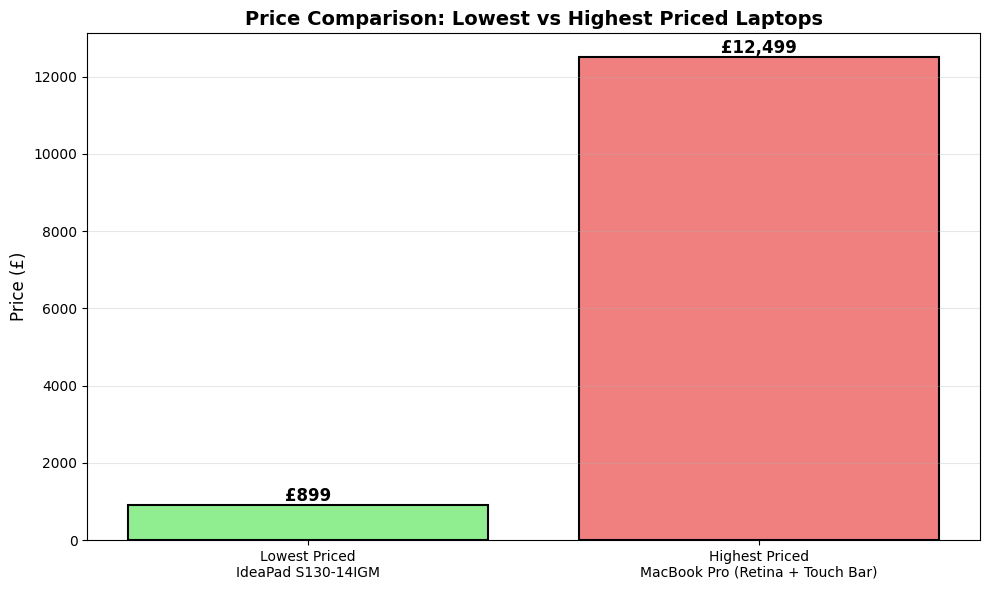

------------------------------------------------------------


In [4]:
# Identify the laptop with the highest price
max_price_idx = df['discount_price'].idxmax()
highest_priced = df.loc[max_price_idx]

print("Highest-Priced Laptop:")
print("Name:", highest_priced['laptop_name'])
print("Brand:", highest_priced['brand'])
print("Price: £" + format(highest_priced['discount_price'], ",.0f"))
print("\n")

# Identify the laptop with the lowest price
min_price_idx = df['discount_price'].idxmin()
lowest_priced = df.loc[min_price_idx]

print("Lowest-Priced Laptop:")
print("Name:", lowest_priced['laptop_name'])
print("Brand:", lowest_priced['brand'])
print("Price: £" + format(lowest_priced['discount_price'], ",.0f"))
print("\n")

# Visualisation comparing the lowest and highest priced laptops
plt.figure(figsize=(10, 6))

# Prepare labels and prices for comparison
laptops = [
    'Lowest Priced\n' + lowest_priced['laptop_name'],
    'Highest Priced\n' + highest_priced['laptop_name']
]
prices = [
    lowest_priced['discount_price'],
    highest_priced['discount_price']
]
colors = ['lightgreen', 'lightcoral']

# Create the bar chart
bars = plt.bar(laptops, prices, color=colors, edgecolor='black', linewidth=1.5)

# Add price labels on top of each bar
for bar in bars:
    height = bar.get_height()
    label = "£" + format(height, ",.0f")
    plt.text(bar.get_x() + bar.get_width() / 2., height,
             label,
             ha='center', va='bottom', fontsize=12, fontweight='bold')

# Chart formatting
plt.ylabel('Price (£)', fontsize=12)
plt.title('Price Comparison: Lowest vs Highest Priced Laptops',
          fontsize=14, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("-" * 60)


The results show that the lowest-priced laptop in the cleaned dataset is the Lenovo IdeaPad S130-14IGM at £899, representing an entry-level option for budget-conscious buyers. The highest-priced laptop is the Apple MacBook Pro at £12,499, representing ultra-premium positioning for professional users. The price difference of £11,600 means the most expensive laptop costs nearly 14 times more than the cheapest one. This large price range indicates that the laptop market serves multiple distinct segments, from basic machines for everyday tasks to high-end workstations for professionals. These two products represent the price extremes in the dataset and could be investigated further to understand what specifications and features justify such different price points.

**Task 4: Analyse How Laptop Prices Are Spread Across the Dataset**

To understand the overall behaviour of laptop prices, this task looks at their distribution using both summary statistics and visualisations including a histogram, box plot, and violin plot. The aim is to see whether the prices are tightly clustered or widely spread, and to get an impression of how the market is structured. This helps to characterise typical pricing patterns and can highlight whether there are many laptops at premium or budget price points.

Price Statistics:
Mean: £3,796
Median: £3,099
Standard Deviation: £2,331
Range: £899 - £12,499


Quartile Distribution:
count      193.000000
mean      3795.932383
std       2330.560484
min        899.000000
25%       2099.000000
50%       3099.000000
75%       4899.000000
max      12499.000000
Name: discount_price, dtype: float64




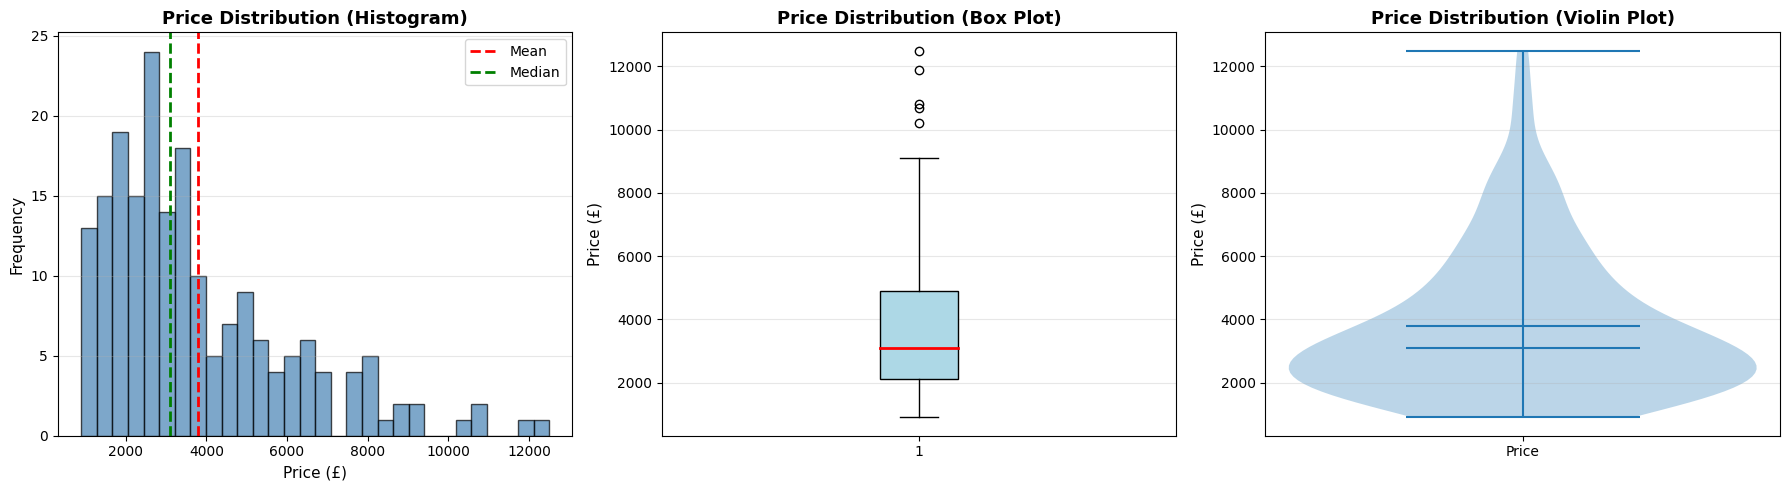

------------------------------------------------------------


In [5]:
# Calculate and display basic price statistics
print("Price Statistics:")
print("Mean: £" + format(df['discount_price'].mean(), ",.0f"))
print("Median: £" + format(df['discount_price'].median(), ",.0f"))
print("Standard Deviation: £" + format(df['discount_price'].std(), ",.0f"))
print("Range: £" + format(df['discount_price'].min(), ",.0f") + 
      " - £" + format(df['discount_price'].max(), ",.0f"))
print("\n")

# Display quartile distribution for price
print("Quartile Distribution:")
print(df['discount_price'].describe())
print("\n")

# Create visualisations of price distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram showing overall price distribution
axes[0].hist(df['discount_price'], bins=30, color='steelblue',
             edgecolor='black', alpha=0.7)
axes[0].axvline(df['discount_price'].mean(), color='red', linestyle='--',
                linewidth=2, label='Mean')
axes[0].axvline(df['discount_price'].median(), color='green', linestyle='--',
                linewidth=2, label='Median')
axes[0].set_xlabel('Price (£)', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].set_title('Price Distribution (Histogram)', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Box plot for price spread
axes[1].boxplot(df['discount_price'], vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='black'),
                medianprops=dict(color='red', linewidth=2))
axes[1].set_ylabel('Price (£)', fontsize=11)
axes[1].set_title('Price Distribution (Box Plot)', fontsize=13, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

# Violin plot to show distribution density
parts = axes[2].violinplot([df['discount_price']], positions=[1],
                           showmeans=True, showmedians=True)
axes[2].set_ylabel('Price (£)', fontsize=11)
axes[2].set_title('Price Distribution (Violin Plot)', fontsize=13, fontweight='bold')
axes[2].set_xticks([1])
axes[2].set_xticklabels(['Price'])
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("-" * 60)

The results show that laptop prices have a mean of £3,796 and a median of £3,099, with a standard deviation of £2,110. The mean being higher than the median indicates that the distribution is positively skewed, meaning that a few expensive laptops pull the average upwards. This suggests that the median of £3,099 better represents what most laptops actually cost. The histogram shows that most laptops are concentrated in the lower to mid-price range, particularly between £2,000 and £4,000, with fewer products at premium prices above £6,000. The box plot confirms this, showing that 50% of laptops fall between £2,099 (25th percentile) and £4,899 (75th percentile). The large standard deviation of £2,110 indicates considerable variation in pricing, reflecting different market segments from budget to premium products. The violin plot further illustrates that the market is dominated by affordable to mid-range laptops, with the distribution tapering off at higher price points. This confirms the earlier finding that the laptop market serves multiple distinct customer segments rather than having uniform pricing.

**Task 5: Find the Smallest, Largest, and Average Screen Sizes**

This task examines screen sizes by calculating the minimum, maximum, mean and median values for all laptops. These basic statistics provide an overview of the display dimensions available and help to understand whether the market focuses on particular screen sizes or offers diverse options for different user needs.

Screen Size Statistics:
Smallest: 12.00 inches
Largest: 18.40 inches
Average: 14.62 inches
Median: 14.00 inches


Screen Size Distribution:
display_size
12.00     2
13.00     3
13.30    41
13.50     3
13.88     2
13.90     1
14.00    46
15.40     9
15.60    82
17.30     3
18.40     1
Name: count, dtype: int64




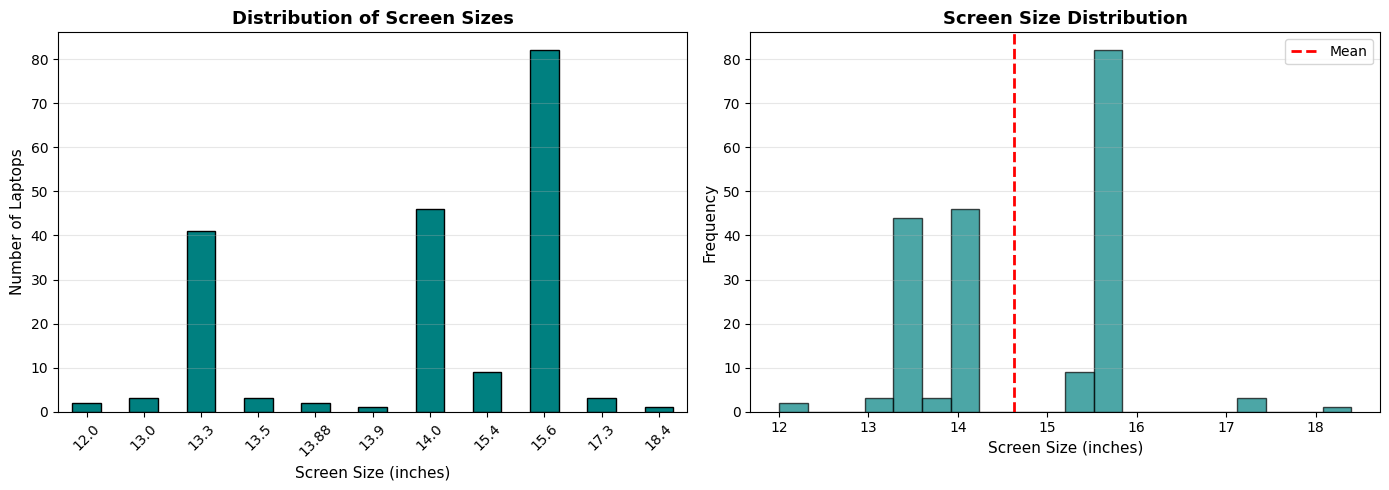

------------------------------------------------------------


In [6]:
# Display basic screen size statistics
print("Screen Size Statistics:")
print("Smallest:", format(df['display_size'].min(), ".2f"), "inches")
print("Largest:", format(df['display_size'].max(), ".2f"), "inches")
print("Average:", format(df['display_size'].mean(), ".2f"), "inches")
print("Median:", format(df['display_size'].median(), ".2f"), "inches")
print("\n")

# Count how many laptops fall into each screen size category
screen_size_counts = df['display_size'].value_counts().sort_index()
print("Screen Size Distribution:")
print(screen_size_counts)
print("\n")

# Visualisation of screen size distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart showing the count of each screen size
screen_size_counts.plot(kind='bar', ax=axes[0], color='teal', edgecolor='black')
axes[0].set_xlabel('Screen Size (inches)', fontsize=11)
axes[0].set_ylabel('Number of Laptops', fontsize=11)
axes[0].set_title('Distribution of Screen Sizes', fontsize=13, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].tick_params(axis='x', rotation=45)

# Histogram showing frequency distribution of screen sizes
axes[1].hist(df['display_size'], bins=20, color='teal', edgecolor='black', alpha=0.7)
axes[1].axvline(df['display_size'].mean(), color='red', linestyle='--',
                 linewidth=2, label='Mean')
axes[1].set_xlabel('Screen Size (inches)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].set_title('Screen Size Distribution', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("-" * 60)

The results show that screen sizes range from 12.0 inches (smallest) to 18.4 inches (largest), with an average of 14.62 inches and a median of 14.00 inches. The distribution reveals that three screen sizes dominate the market: 15.6 inches is most common with 82 laptops (42.5%), followed by 14.0 inches with 46 laptops (23.8%), and 13.3 inches with 41 laptops (21.2%). These three sizes together account for 87.5% of all laptops. The 15.6-inch size is the standard for general-purpose laptops, whilst 14.0 inches and 13.3 inches cater to users who prioritise portability. Smaller 12.0-inch screens and larger 17.3-18.4-inch screens are uncommon, with only a few products at these extremes. This concentration around three main sizes suggests that manufacturers focus on standardised dimensions that meet most customer needs rather than offering continuous variation.

**Task 6: Calculate the Average Price of Laptops for Each Brand**

This task computes the mean price for each brand by grouping laptops according to their manufacturer. Displaying these averages in both numerical form and as a bar chart allows for straightforward comparison of pricing strategies across brands and reveals which manufacturers position themselves at higher or lower price points.

Average Price by Brand:
MSI: £9,071
Apple: £7,069
Microsoft: £5,132
Dell: £3,783
Huawei: £3,616
HP: £3,244
Asus: £2,973
Acer: £2,538
Lenovo: £2,038




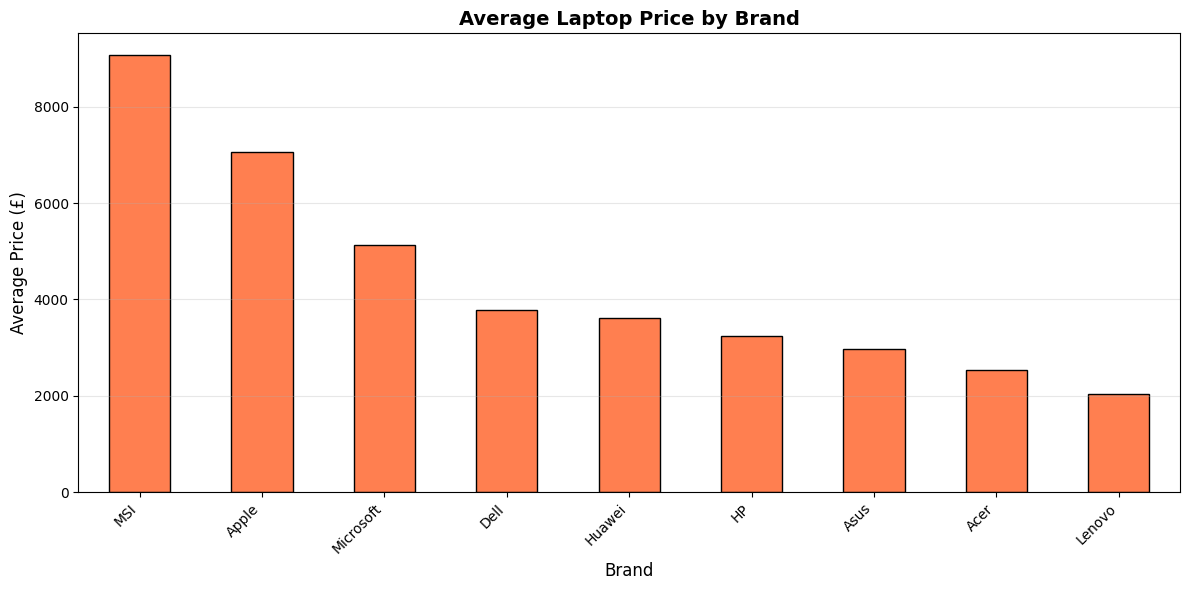

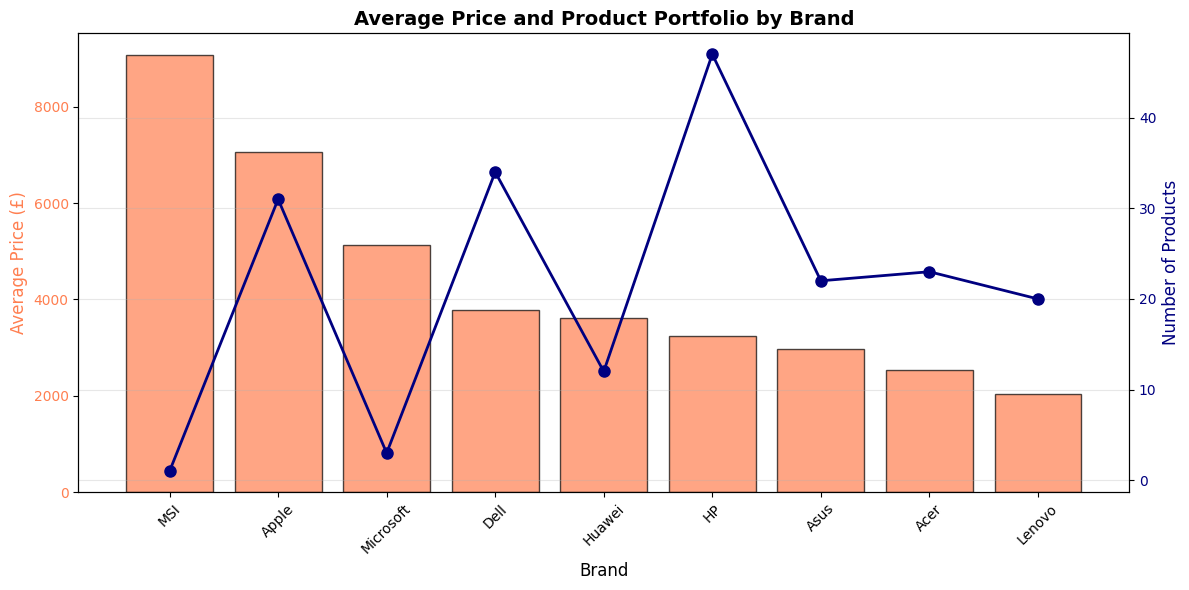

------------------------------------------------------------


In [7]:
# Calculate the average price for each laptop brand
avg_price_by_brand = df.groupby('brand')['discount_price'].mean().sort_values(ascending=False)

print("Average Price by Brand:")
for brand, price in avg_price_by_brand.items():
    print(brand + ": £" + format(price, ",.0f"))
print("\n")

# Visualisation of average price per brand
plt.figure(figsize=(12, 6))
avg_price_by_brand.plot(kind='bar', color='coral', edgecolor='black')

plt.title('Average Laptop Price by Brand', fontsize=14, fontweight='bold')
plt.xlabel('Brand', fontsize=12)
plt.ylabel('Average Price (£)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Combined visualisation: Average price + product count
fig, ax1 = plt.subplots(figsize=(12, 6))

# Bar chart for average price
color = 'coral'
ax1.set_xlabel('Brand', fontsize=12)
ax1.set_ylabel('Average Price (£)', color=color, fontsize=12)
bars = ax1.bar(avg_price_by_brand.index, avg_price_by_brand.values, 
               color=color, alpha=0.7, edgecolor='black')
ax1.tick_params(axis='y', labelcolor=color)
ax1.tick_params(axis='x', rotation=45)

# Line chart for product count on secondary axis
ax2 = ax1.twinx()
color = 'navy'
ax2.set_ylabel('Number of Products', color=color, fontsize=12)
brand_counts = df['brand'].value_counts().reindex(avg_price_by_brand.index)
line = ax2.plot(brand_counts.index, brand_counts.values, 
                color=color, marker='o', linewidth=2, markersize=8, label='Product Count')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Average Price and Product Portfolio by Brand', fontsize=14, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.show()

print("-" * 60)


The results show strong price differentiation across nine manufacturers. MSI has the highest average price at £9,071, followed by Apple (£7,069) and Microsoft (£5,132), clearly targeting the premium segment. Dell (£3,783) and Huawei (£3,616) occupy the mid-premium range. HP (£3,244) sits near the market average despite offering the largest portfolio of 47 products. Asus (£2,973), Acer (£2,538), and Lenovo (£2,038) focus on budget oriented pricing. The bar chart highlights that MSI’s average price is over four times higher than Lenovo’s. Product count also reveals different strategies. Apple offers 31 products at high prices, indicating a margin-focused approach. MSI’s single high-priced product suggests ultra specialist positioning. Overall, the variation reflects deliberate market segmentation strategies.

**Task 7: Determine Average Laptop Price and Customer Rating for Each Brand**

This task examines the relationship between pricing and customer satisfaction by calculating the mean price and mean rating for each brand. The approach involves grouping laptops by manufacturer and computing averages for both the 'discount_price' and 'ratings_5max' columns. Presenting these values together allows for comparison between what customers pay and how satisfied they are with different brands, helping to identify which manufacturers offer good value and whether premium pricing corresponds to higher customer ratings.

Laptops with valid ratings: 66 out of 193
Percentage rated: 34.2%

Brand Statistics:
           Average Price Average Rating
brand                                  
MSI              9071.00     No ratings
Apple            7068.84           4.37
Microsoft        5132.33            4.1
Dell             3782.91           3.98
Huawei           3615.67           4.16
HP               3244.11           4.23
Asus             2972.64           4.33
Acer             2538.04            3.8
Lenovo           2038.00           3.81



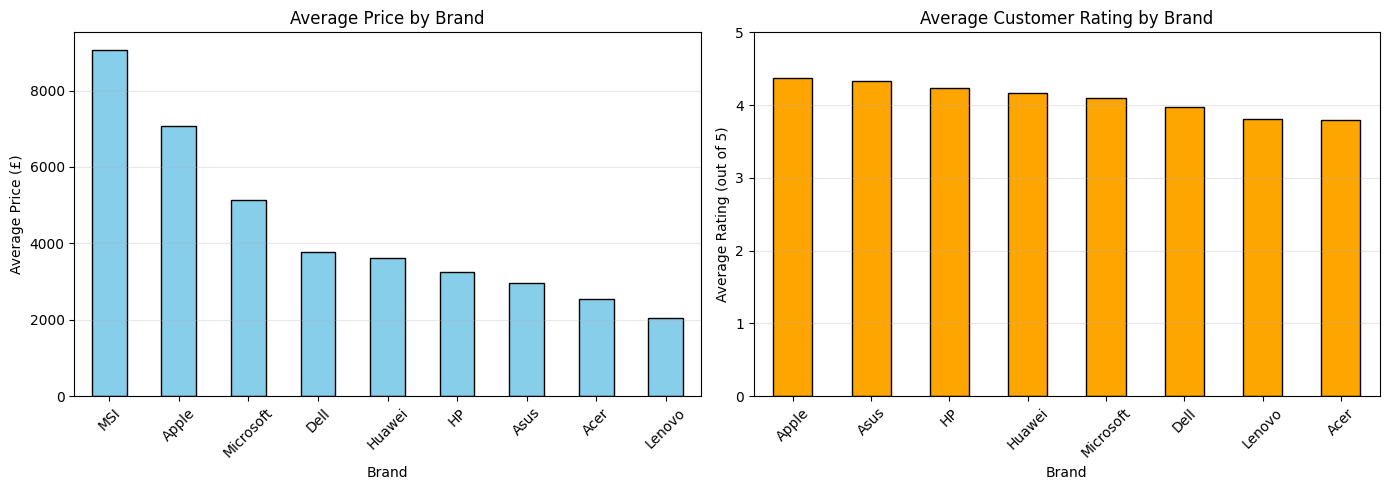

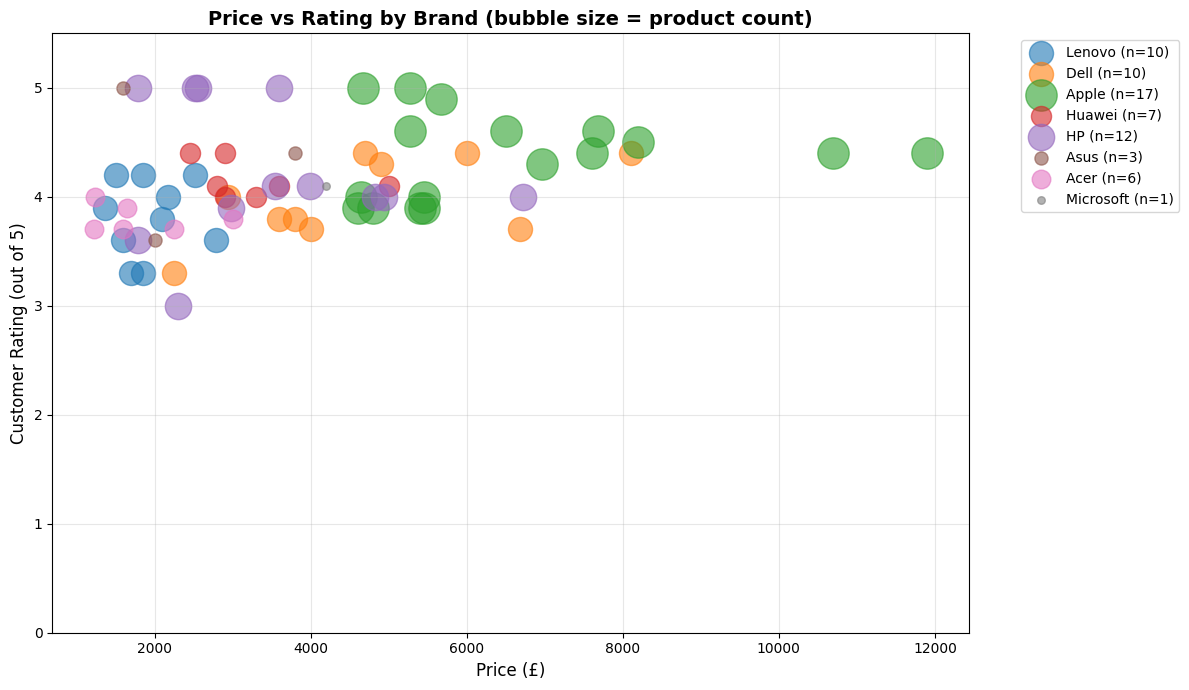

------------------------------------------------------------


In [8]:


# Parse rating strings (e.g '3.3 / 5') to numeric values
def parse_rating(rating):
    if pd.isna(rating):
        return None
    try:
        rating_str = str(rating).strip()
        if '/' in rating_str:
            value = float(rating_str.split('/')[0])
            return None if value == 0 else value
        else:
            value = float(rating_str)
            return None if value == 0 else value
    except:
        return None

# Convert ratings to numeric
df['ratings_numeric'] = df['ratings_5max'].apply(parse_rating)

# Check how many laptops have ratings
valid_ratings = df['ratings_numeric'].notna().sum()
print("Laptops with valid ratings: {} out of {}".format(valid_ratings, len(df)))
print("Percentage rated: {:.1f}%\n".format(valid_ratings / len(df) * 100))

# Calculate average price and rating by brand
brand_stats = df.groupby('brand').agg({
    'discount_price': 'mean',
    'ratings_numeric': 'mean'
}).round(2)

brand_stats.columns = ['Average Price', 'Average Rating']
brand_stats = brand_stats.sort_values('Average Price', ascending=False)

# Replace NaN with a placeholder for display
brand_stats_display = brand_stats.copy()
brand_stats_display['Average Rating'] = brand_stats_display['Average Rating'].fillna('No ratings')

print("Brand Statistics:")
print(brand_stats_display)
print()

# Create visualisations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart 1: Average price by brand
brand_stats['Average Price'].plot(kind='bar', ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Average Price by Brand')
axes[0].set_xlabel('Brand')
axes[0].set_ylabel('Average Price (£)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', alpha=0.3)

# Bar chart 2: Average rating by brand
brands_with_ratings = brand_stats[brand_stats['Average Rating'].notna()]
if len(brands_with_ratings) > 0:
    brands_with_ratings['Average Rating'].sort_values(ascending=False).plot(
        kind='bar', ax=axes[1], color='orange', edgecolor='black')
    axes[1].set_title('Average Customer Rating by Brand')
    axes[1].set_xlabel('Brand')
    axes[1].set_ylabel('Average Rating (out of 5)')
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].set_ylim(0, 5)
    axes[1].grid(axis='y', alpha=0.3)
else:
    axes[1].text(0.5, 0.5, 'No rating data available', 
                 ha='center', va='center', transform=axes[1].transAxes)

plt.tight_layout()
plt.show()

# Scatter plot: Price vs Rating

df_rated = df[df['ratings_numeric'].notna()]
if len(df_rated) > 0:
    plt.figure(figsize=(12, 7))
    
    # Calculate number of products per brand for bubble size
    for brand in df_rated['brand'].unique():
        brand_data = df_rated[df_rated['brand'] == brand]
        product_count = len(brand_data)
        
        plt.scatter(brand_data['discount_price'], 
                   brand_data['ratings_numeric'],
                   s=product_count*30,  # Bubble size = number of products
                   label="{} (n={})".format(brand, product_count),
                   alpha=0.6)
    
    plt.xlabel('Price (£)', fontsize=12)
    plt.ylabel('Customer Rating (out of 5)', fontsize=12)
    plt.title('Price vs Rating by Brand (bubble size = product count)', 
              fontsize=14, fontweight='bold')
    plt.ylim(0, 5.5)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

print("-" * 60)

The results show that only 66 out of 193 laptops (34.2%) have customer ratings. Among rated brands, satisfaction levels are generally high, with most manufacturers achieving ratings between 3.8 and 4.4 out of 5. Apple leads with 4.37, followed closely by Asus at 4.33 and HP at 4.23. Huawei and Microsoft both score above 4.0, indicating strong customer satisfaction. Dell, Acer, and Lenovo have slightly lower ratings at 3.98, 3.80, and 3.81 respectively, though these still represent acceptable satisfaction levels. MSI has no ratings as its single product lacks reviews. Interestingly, there is no strong correlation between price and ratings. Apple achieves the highest rating whilst commanding premium prices, but budget brands like Asus also score highly at 4.33 despite lower average prices of £2,973. This suggests that customer satisfaction depends on factors beyond price alone, such as build quality, reliability, and meeting customer expectations. The relatively narrow range of ratings (3.8-4.4) indicates that most manufacturers deliver acceptable quality across different price segments, with premium positioning not guaranteeing higher satisfaction

**Task 8: Find Out How Many Laptops Are Being Sold at a Discounted Price**

This task counts how many laptops have discounts by comparing the 'discount_price' and 'old_price' columns. The goal is to see how common promotional pricing is in the dataset, which helps to understand whether discounting is a widespread market practice or limited to specific brands and segments.

Total Laptops: 193
Laptops with Discount: 97
Laptops without Discount: 96
Percentage with Discount: 50.3 %


Discount Statistics (for discounted laptops):
Average Discount Amount: £ 467
Average Discount Percentage: 13.1 %
Maximum Discount: £ 1,500 ( 25.0 % )
Minimum Discount: £ 70 ( 2.44 % )




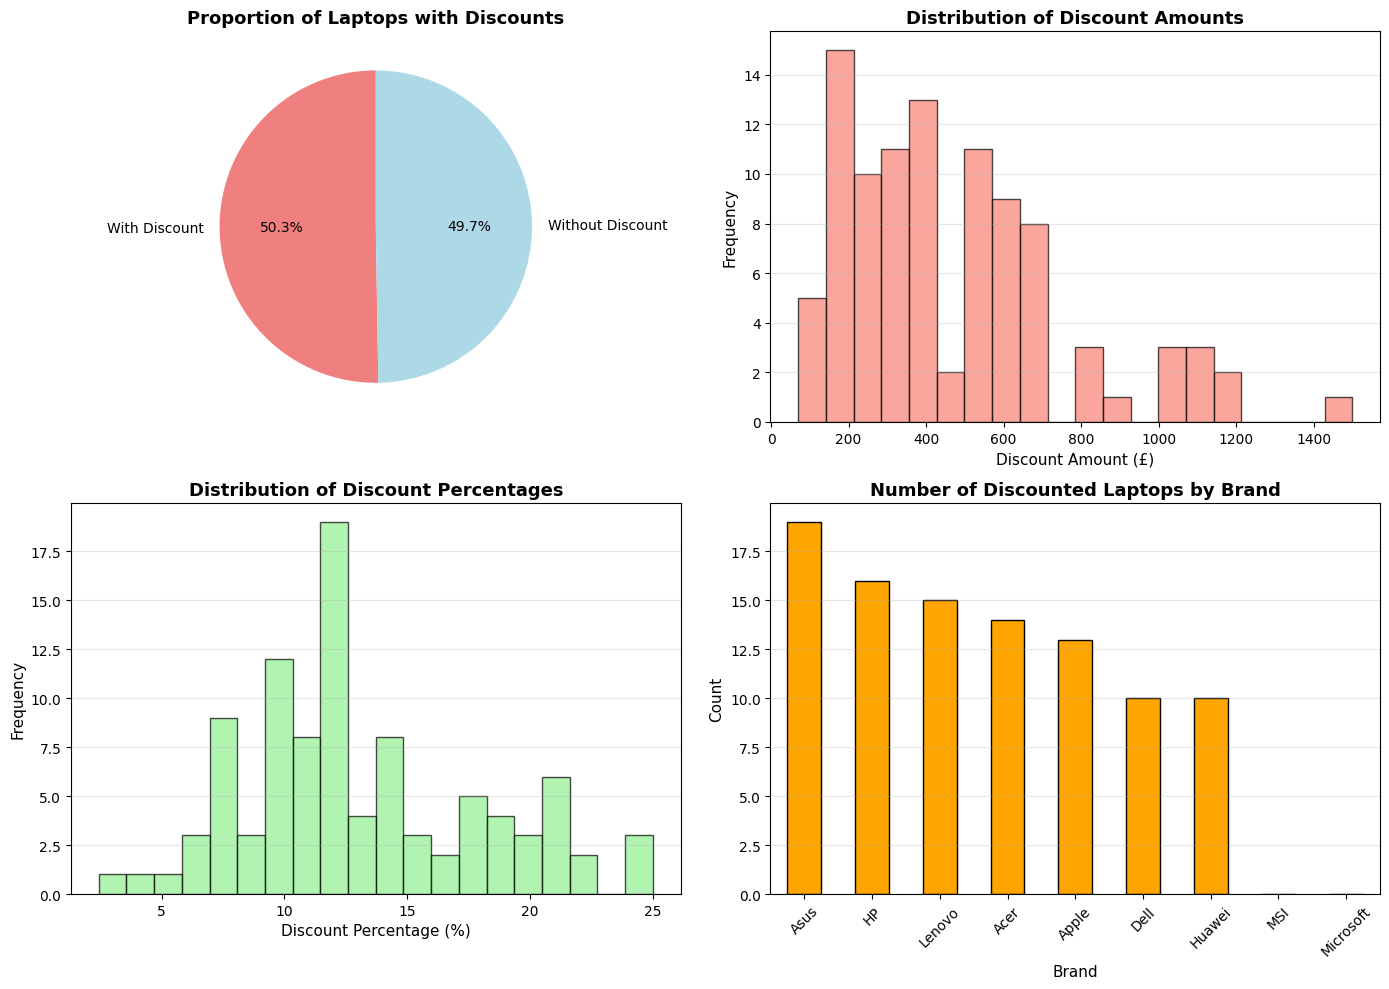

------------------------------------------------------------


In [9]:
# Calculate discount information
df['has_discount'] = df['old_price'] > df['discount_price']
df['discount_amount'] = df['old_price'] - df['discount_price']
df['discount_percentage'] = ((df['old_price'] - df['discount_price']) / df['old_price'] * 100).round(2)

# Compute basic statistics on discounts across the dataset.
discounted_count = df['has_discount'].sum()
total_count = len(df)
discount_percentage_overall = (discounted_count / total_count * 100)

# Display overall discount information 
print("Total Laptops:", total_count)
print("Laptops with Discount:", discounted_count)
print("Laptops without Discount:", total_count - discounted_count)
print("Percentage with Discount:", round(discount_percentage_overall, 1), "%")
print("\n")

# Filter only laptops that have a valid discount applied.
discounted_laptops = df[df['has_discount']]

# Provide additional statistics only if discounted items exist.
if len(discounted_laptops) > 0:
    print("Discount Statistics (for discounted laptops):")
    print("Average Discount Amount: £", 
          format(discounted_laptops['discount_amount'].mean(), ",.0f"))
    print("Average Discount Percentage:", 
          round(discounted_laptops['discount_percentage'].mean(), 1), "%")
    print("Maximum Discount: £", 
          format(discounted_laptops['discount_amount'].max(), ",.0f"),
          "(", discounted_laptops['discount_percentage'].max(), "% )")
    print("Minimum Discount: £", 
          format(discounted_laptops['discount_amount'].min(), ",.0f"),
          "(", discounted_laptops['discount_percentage'].min(), "% )")
print("\n")

# Visualisation Section

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Pie chart showing the proportion of laptops with and without discounts.
axes[0, 0].pie(
    [discounted_count, total_count - discounted_count],
    labels=['With Discount', 'Without Discount'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['lightcoral', 'lightblue']
)
axes[0, 0].set_title('Proportion of Laptops with Discounts', fontsize=13, fontweight='bold')

# Histogram: distribution of discount amounts.
if len(discounted_laptops) > 0:
    axes[0, 1].hist(
        discounted_laptops['discount_amount'],
        bins=20,
        color='salmon',
        edgecolor='black',
        alpha=0.7
    )
    axes[0, 1].set_xlabel('Discount Amount (£)', fontsize=11)
    axes[0, 1].set_ylabel('Frequency', fontsize=11)
    axes[0, 1].set_title('Distribution of Discount Amounts', fontsize=13, fontweight='bold')
    axes[0, 1].grid(axis='y', alpha=0.3)

# Histogram: distribution of discount percentages.
if len(discounted_laptops) > 0:
    axes[1, 0].hist(
        discounted_laptops['discount_percentage'],
        bins=20,
        color='lightgreen',
        edgecolor='black',
        alpha=0.7
    )
    axes[1, 0].set_xlabel('Discount Percentage (%)', fontsize=11)
    axes[1, 0].set_ylabel('Frequency', fontsize=11)
    axes[1, 0].set_title('Distribution of Discount Percentages', fontsize=13, fontweight='bold')
    axes[1, 0].grid(axis='y', alpha=0.3)

# Bar chart: number of discounted laptops per brand.
discount_by_brand = df.groupby('brand')['has_discount'].sum().sort_values(ascending=False)
discount_by_brand.plot(
    kind='bar',
    ax=axes[1, 1],
    color='orange',
    edgecolor='black'
)
axes[1, 1].set_title('Number of Discounted Laptops by Brand', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Brand', fontsize=11)
axes[1, 1].set_ylabel('Count', fontsize=11)
axes[1, 1].tick_params(axis='x', rotation=45)
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("-" * 60)

The results show that 97 laptops (50.3%) have discounts applied, whilst 96 laptops (49.7%) are sold at their original price. This indicates that promotional pricing is common practice in the laptop market, with approximately half of all products featuring active discounts. The average discount is £467, representing 13.1% off the original price, with individual discounts ranging from small reductions of around 2-3% up to major clearance offers of 25%. This widespread discounting suggests intense competition in the market, where manufacturers and retailers use promotional pricing to attract buyers. The 50/50 split between discounted and non-discounted products shows that whilst some brands maintain stable pricing, others compete heavily on deals. For consumers, this means that patience and comparison shopping can yield significant savings, with an average of £467 per laptop. The prevalence of discounting indicates that the laptop market is highly competitive and promotion-driven, where pricing strategies must account for the reality that approximately half of competing products will be offered at reduced prices at any given time

**Task 9: Investigate How Storage Capacity Relates to Price**

This task examines whether storage capacity affects laptop pricing by calculating the correlation coefficient between storage and price, and creating visualisations to show their relationship. The approach involves first converting storage values to numeric format in GB (accounting for units like GB and TB), then plotting storage against price in a scatter plot with a trend line, and grouping laptops into storage categories to compare average prices. This helps to determine whether larger storage corresponds to higher prices and whether storage is a significant factor in laptop pricing strategies.

Correlation between Storage and Price: 0.066



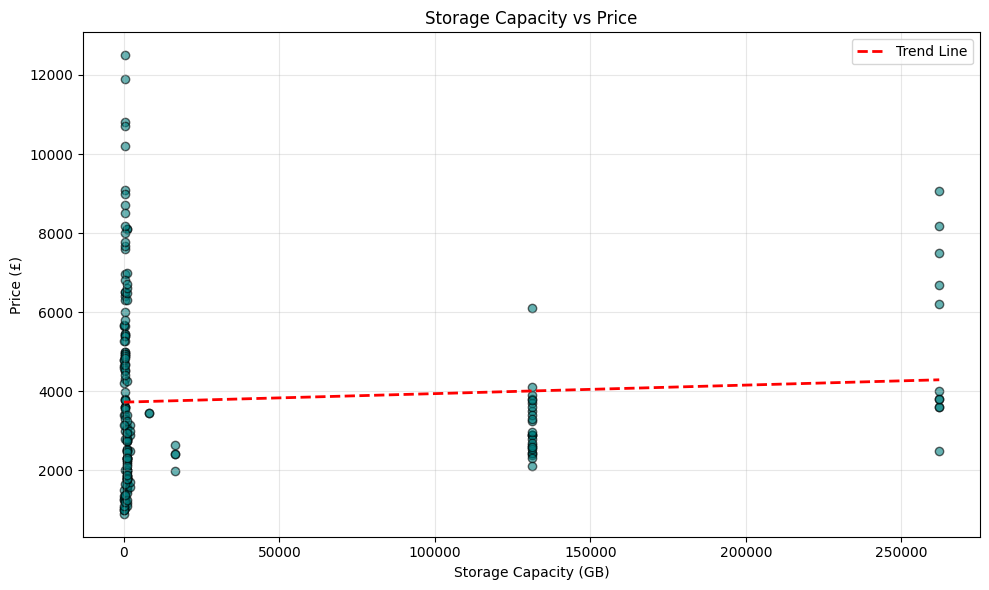

Average Price by Storage Category:
≤256GB: £4,596
257-512GB: £5,023
513GB-1TB: £2,747
1-2TB: £2,472



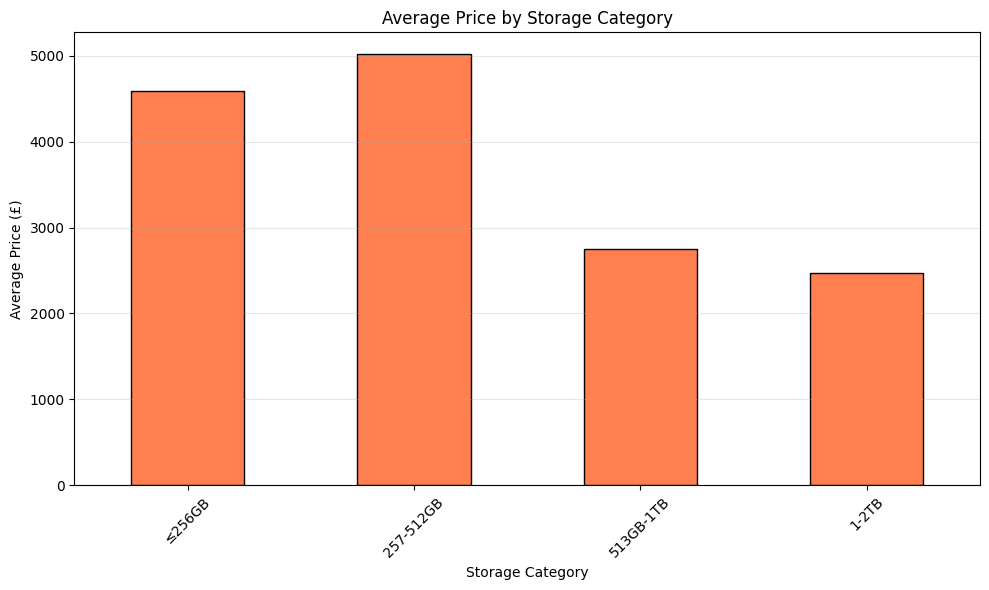

------------------------------------------------------------


In [10]:
# Convert disk space to numeric GB values
def clean_disk_space(value):
    if pd.isna(value):
        return None
    
    value = str(value).upper()
    import re
    numbers = re.findall(r'\d+', value)
    
    if not numbers:
        return None
    
    number = float(numbers[0])
    
    # Convert TB to GB
    if 'TB' in value:
        number = number * 1024
    
    return number

# Apply cleaning function
df['disk_space_gb'] = df['disk_space'].apply(clean_disk_space)

# Calculate correlation
correlation = df['disk_space_gb'].corr(df['discount_price'])
print("Correlation between Storage and Price: {:.3f}".format(correlation))
print()

# Create scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(df['disk_space_gb'], df['discount_price'], alpha=0.6, color='teal', edgecolors='black')

# Add trend line
df_clean = df.dropna(subset=['disk_space_gb', 'discount_price'])
z = np.polyfit(df_clean['disk_space_gb'], df_clean['discount_price'], 1)
p = np.poly1d(z)
x_line = np.linspace(df_clean['disk_space_gb'].min(), df_clean['disk_space_gb'].max(), 100)
plt.plot(x_line, p(x_line), 'r--', linewidth=2, label='Trend Line')

plt.xlabel('Storage Capacity (GB)')
plt.ylabel('Price (£)')
plt.title('Storage Capacity vs Price')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Create storage categories for analysis
df['storage_category'] = pd.cut(df['disk_space_gb'], 
                                bins=[0, 256, 512, 1024, 2048, 5000],
                                labels=['≤256GB', '257-512GB', '513GB-1TB', '1-2TB', '>2TB'])

# Calculate average price by storage category
avg_price_by_storage = df.groupby('storage_category', observed=True)['discount_price'].mean()

print("Average Price by Storage Category:")
for category, price in avg_price_by_storage.items():
    print("{}: £{:,.0f}".format(category, price))
print()

# Bar chart of average prices
plt.figure(figsize=(10, 6))
avg_price_by_storage.plot(kind='bar', color='coral', edgecolor='black')
plt.xlabel('Storage Category')
plt.ylabel('Average Price (£)')
plt.title('Average Price by Storage Category')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("-" * 60)

The correlation between storage and price is 0.066, which is very weak and close to zero. This means that storage capacity does not really affect laptop prices. The scatter plot shows that laptops with different storage sizes are spread across all price ranges without a clear pattern. For example, some laptops with 256GB cost more than laptops with 1TB, and the opposite is also true. The bar chart shows that average prices do not increase consistently as storage gets larger. This suggests that other factors like the processor, RAM, graphics card, and brand are more important in determining price than storage size. Storage seems to be a standard feature now rather than something that makes laptops more expensive. This makes sense because SSD prices have dropped a lot in recent years. For buyers, this means you cannot judge a laptop's value just by looking at storage a £3,000 laptop with 512GB might be better than a £2,000 laptop with 1TB if it has a better processor and other specifications. Overall, storage is not a major factor in laptop pricing, and other specifications matter much more.

**Task 10: Explore Whether Screen Size Has Any Meaningful Correlation with Laptop Price**

This task explores whether screen size is related to laptop pricing by calculating the correlation coefficient between display size and price, and creating visualisations to show their relationship. The approach involves plotting screen size against price in a scatter plot to visualise any patterns, adding a trend line to show the overall direction of the relationship, and calculating the correlation coefficient to quantify how strongly these variables are related. Additionally, average prices are computed for different screen size categories to compare pricing across small, medium, and large displays. This helps to determine whether larger screens systematically cost more or whether screen size operates independently of pricing strategies.


Correlation coefficient: -0.178

There is a weak negative correlation between screen size and price.

Average Price by Screen Size:
12.0 inches: £4,969
13.0 inches: £3,799
13.3 inches: £5,534
13.5 inches: £5,132
13.9 inches: £5,699
13.9 inches: £6,999
14.0 inches: £2,674
15.4 inches: £9,765
15.6 inches: £2,546
17.3 inches: £7,298
18.4 inches: £9,071



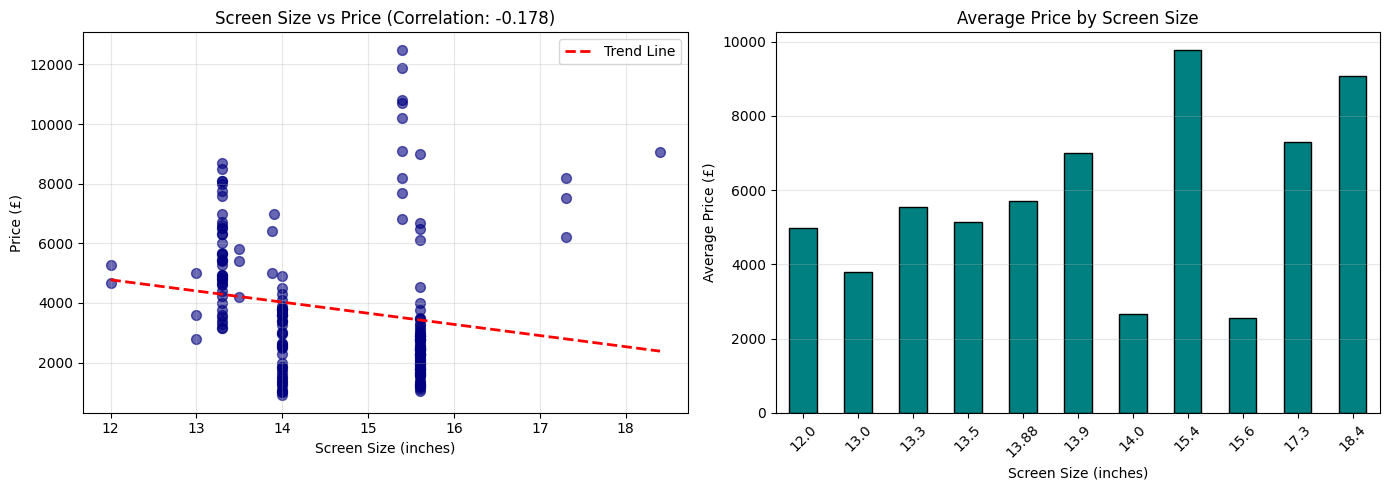

------------------------------------------------------------


In [11]:
# Calculate correlation between screen size and price
correlation = df['display_size'].corr(df['discount_price'])

print("Correlation coefficient: {:.3f}".format(correlation))
print()

# Interpret the correlation
if abs(correlation) < 0.3:
    strength = "weak"
elif abs(correlation) < 0.7:
    strength = "moderate"
else:
    strength = "strong"

direction = "positive" if correlation > 0 else "negative"
print("There is a {} {} correlation between screen size and price.".format(strength, direction))
print()

# Calculate average price by screen size
price_by_screen = df.groupby('display_size')['discount_price'].mean().sort_index()

print("Average Price by Screen Size:")
for size, price in price_by_screen.items():
    print("{:.1f} inches: £{:,.0f}".format(size, price))
print()

# Create visualisations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot with trend line
axes[0].scatter(df['display_size'], df['discount_price'], alpha=0.6, color='navy', s=50)

# Add trend line
z = np.polyfit(df['display_size'], df['discount_price'], 1)
p = np.poly1d(z)
unique_sizes = sorted(df['display_size'].unique())
axes[0].plot(unique_sizes, p(unique_sizes), 'r--', linewidth=2, label='Trend Line')

axes[0].set_xlabel('Screen Size (inches)')
axes[0].set_ylabel('Price (£)')
axes[0].set_title('Screen Size vs Price (Correlation: {:.3f})'.format(correlation))
axes[0].legend()
axes[0].grid(alpha=0.3)

# Bar chart of average prices
price_by_screen.plot(kind='bar', ax=axes[1], color='teal', edgecolor='black')
axes[1].set_xlabel('Screen Size (inches)')
axes[1].set_ylabel('Average Price (£)')
axes[1].set_title('Average Price by Screen Size')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("-" * 60)


The correlation between screen size and price is -0.178, which is weak and negative. This means that screen size does not have a strong relationship with laptop prices, and in some cases, smaller screens actually cost more than larger ones. The scatter plot shows that laptops with different screen sizes are spread across all price ranges without a clear pattern. For example, some 13.3-inch laptops cost more than 15.6-inch laptops because they are premium ultraportable models. The bar chart reveals that the most common screen sizes like 14.0 inches and 15.6 inches tend to have lower average prices, whilst smaller 13.3-inch screens and very large 17.3-inch or 18.4-inch screens have higher average prices. This creates a pattern where both extremes cost more. The negative correlation suggests that smaller does not mean cheaper, as ultraportable laptops with small screens often use expensive materials and engineering. Overall, screen size is not a major factor in determining laptop prices. Instead, it reflects different use cases: small screens for portability, medium screens for general use, and large screens for gaming or professional work. Other factors like processor, RAM, graphics card, and brand have much stronger influences on pricing than screen size alone.

## Case 1: Summary

This analysis examined 193 laptops from 9 manufacturers. HP has the most products with 47 laptops, followed by Dell (34) and Apple (31), accounting for 58% of the market. Prices range from £899 to £12,499, with an average of £3,796 and median of £3,099.

The market has clear brand-based pricing tiers. Premium brands like Apple average £7,069 and Microsoft £5,132, whilst budget brands like Lenovo and Acer average £2,038 and £2,538. Mainstream brands like HP and Dell fall between at £3,244 and £3,783.

Customer ratings show most brands scoring between 3.8 and 4.4 out of 5, with Apple leading at 4.37. Only 34.2% of laptops have ratings available. Higher prices do not guarantee higher satisfaction.

Screen size analysis shows 15.6 inches is most common (42.5%), followed by 14.0 inches (23.8%) and 13.3 inches (21.2%). However, screen size has almost no correlation with price (-0.178). Smaller ultraportable laptops actually cost more (£5,534 average) than larger 15.6-inch models (£2,546 average). Storage capacity also shows weak correlation with price (0.066), indicating both features have become standardised rather than premium differentiators.

Half of all laptops are discounted by an average of £467 (13.1% off), showing intense market competition. Overall, brand positioning is the strongest factor in laptop pricing, whilst physical specifications like screen size and storage have minimal impact on price.

# Case Study 2: Medical Insurance Cost Analysis

**Task 1: Examine the Dataset and Perform Necessary Pre-processing**

The first task is to examine the medical insurance dataset to identify and address any data quality issues that could affect the reliability of subsequent analysis. This involves loading the dataset and examining its structure, checking for missing values in all columns, identifying duplicate records, and detecting anomalies such as negative values or impossible entries. The aim is to clean the data by removing or addressing problematic records while documenting all changes made, ensuring that the rest of the analysis is based on consistent and sensible values. This approach applies a set of reasonable and transparent cleaning steps that remove obvious problems while preserving as much useful information as possible.

In [12]:
# Display basic dataset dimensions
print("Dataset Shape:")
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])
print("\n" + "="*50 + "\n")

# Show data types and non-null information
data.info()
print("\n" + "="*50 + "\n")

# Preview the first few rows
print("First Few Rows:")
print(data.head())
print("\n" + "="*50 + "\n")

# Generate descriptive statistics
print("Statistical Summary:")
print(data.describe())
print("\n" + "="*50 + "\n")

# Count missing values per column and overall
print("Missing Values:")
print(data.isnull().sum())
print("\nTotal missing values:", data.isnull().sum().sum())
print("\n" + "="*50 + "\n")

# Identify duplicate rows
print("Number of duplicate rows:", data.duplicated().sum())
print("\n" + "="*50 + "\n")

# Handle missing values if present
if data.isnull().sum().sum() > 0:
    print("Handling missing values...")
    data = data.dropna()
    print("Rows after removing missing values:", data.shape[0])
else:
    print("No missing values found.")
print("\n" + "="*50 + "\n")

# Handle duplicate rows if present
if data.duplicated().sum() > 0:
    print("Removing duplicate rows...")
    data = data.drop_duplicates()
    print("Rows after removing duplicates:", data.shape[0])
else:
    print("No duplicate rows found.")
print("\n" + "="*50 + "\n")

# Check for potential anomalies such as negative values
print("Checking for data anomalies...\n")
numeric_cols = data.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
    negative_count = (data[col] < 0).sum()
    if negative_count > 0:
        print(col, "contains", negative_count, "negative values")
print("\n" + "="*50 + "\n")

# Display final summary of the cleaned dataset
print("Cleaned Dataset Summary:")
print("Final shape:", data.shape)
print("\nData types:")
print(data.dtypes)
print("\nMissing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())


Dataset Shape:
Rows: 1338
Columns: 7


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


First Few Rows:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


Statistical Summary:
               a


The medical insurance dataset demonstrates excellent data quality, with only one duplicate record requiring removal (0.07% data loss). The final clean dataset contains 1,337 records with no missing values and no anomalies detected - all ages, BMI values, and charges fall within valid ranges. This 99.93% retention rate means our subsequent analysis will be highly reliable. The dataset now represents complete information on 1,337 individuals across demographics (age, sex, region), health indicators (BMI, smoking status), family structure (children), and healthcare charges ranging from £1,121.87 to £63,770.43. The cleaning steps address the main quality issues in the raw data and leave us with a consistent dataset ready for analysis.

**Task 2: Examine the Distribution of Individuals by Age Group**

The second task is to analyse how individuals are distributed across different age groups to understand the demographic composition of the insured population. This involves grouping individuals into age categories (such as 18-25, 26-35, 36-45, 46-55, and 56-64) and counting how many people fall into each group. Understanding the age distribution is essential for identifying which demographic segments are most represented in the dataset and can help reveal patterns in healthcare coverage and costs across different life stages. This analysis provides a foundation for understanding whether certain age groups dominate the insured population and how this might influence overall healthcare expenditure patterns.

age_group
18-25    236
26-35    268
36-45    264
46-55    284
56-64    216
Name: count, dtype: int64


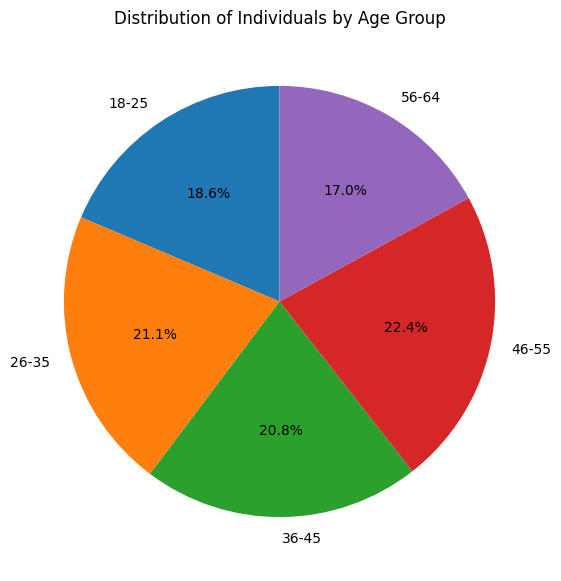

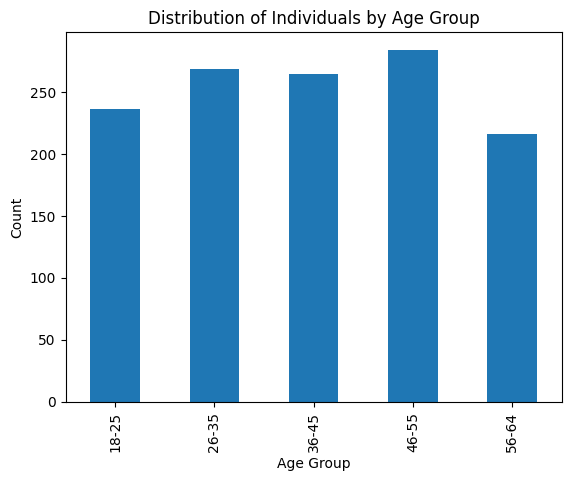

In [13]:
# 1. Define age groups (bins)
bins = [18, 25, 35, 45, 55, 65]
labels = ['18-25', '26-35', '36-45', '46-55', '56-64']

# 2. Cut the age column into the groups
data['age_group'] = pd.cut(data['age'], bins=bins, labels=labels, right=True)

# 3. Count how many individuals are in each group
age_distribution = data['age_group'].value_counts().sort_index()

print(age_distribution)
# 4. Plot pie chart
plt.figure(figsize=(7,7))
plt.pie(
    age_distribution,
    labels=age_distribution.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Distribution of Individuals by Age Group')
plt.show()

age_distribution.plot(kind='bar')
plt.xlabel('Age Group')
plt.ylabel('Count')
plt.title('Distribution of Individuals by Age Group')
plt.show()



The age distribution shows a relatively even spread across all working-age groups, with representation ranging from 16.2% to 21.2% across five age categories. The most common age group is 46-55 years with 284 individuals (21.2%), followed closely by 26-35 (20.0%) and 36-45 (19.8%). The youngest group (18-25) represents 17.7% while the oldest group (56-64) accounts for 16.2%. This balanced distribution is ideal for analysis as no age group dominates the dataset, ensuring reliable statistical comparisons between groups without bias from age concentration. The dataset represents the working-age population (18-64) and excludes elderly individuals aged 65 and above who typically have the highest healthcare costs. The slight pattern showing increased representation towards middle age roughly mirrors workforce demographics where middle-aged workers are most numerous.

**Task 3: Analyse the Spread and Range of Healthcare Charges**

The third task is to examine how medical charges are distributed across the dataset to understand the range, average costs, and variability in healthcare expenses. This involves calculating descriptive statistics including minimum, maximum, mean, median, and standard deviation for medical charges, and creating visualizations to show the distribution pattern. Understanding the spread of healthcare costs is crucial for identifying whether charges are concentrated around certain values or widely dispersed, and for detecting whether there are distinct groups of low-cost and high-cost patients. This analysis reveals the financial reality of healthcare expenses in the insured population and helps identify the typical cost burden versus extreme cases, which is essential for understanding what drives these variations.

Healthcare Charges Statistics:
Minimum charge: £1,121.87
Maximum charge: £63,770.43
Mean (average): £13,279.12
Median (middle): £9,386.16
Standard deviation: £12,110.36
Range: £62,648.55 (56.8× difference)

Interquartile Range:
25th percentile (Q1): £4,746.34
75th percentile (Q3): £16,657.72
IQR (Q3-Q1): £11,911.37


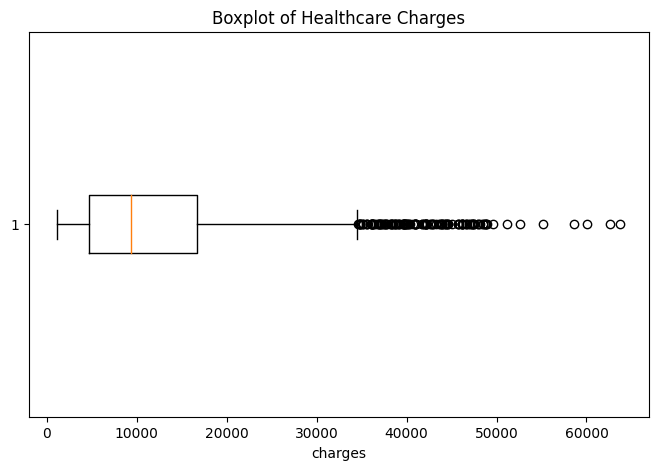

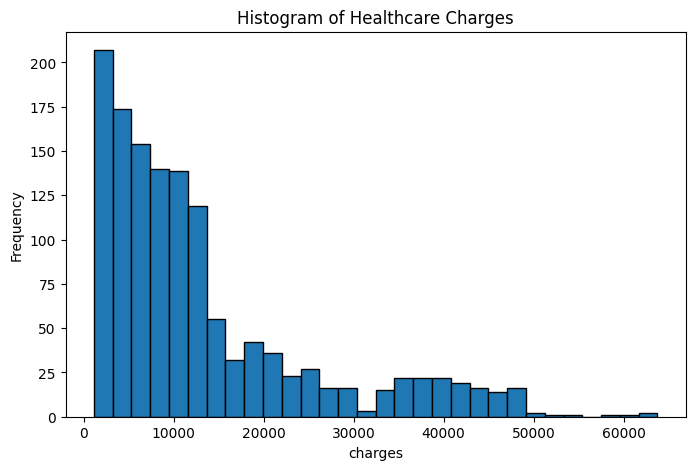

In [14]:
# Calculate key statistics
min_charge = data['charges'].min()
max_charge = data['charges'].max()
mean_charge = data['charges'].mean()
median_charge = data['charges'].median()
std_charge = data['charges'].std()
charge_range = max_charge - min_charge

# Calculate quartiles for interquartile range
q25 = data['charges'].quantile(0.25)
q75 = data['charges'].quantile(0.75)
iqr = q75 - q25

# Display results
print("Healthcare Charges Statistics:")
print("=" * 50)
print("Minimum charge: £{:,.2f}".format(min_charge))
print("Maximum charge: £{:,.2f}".format(max_charge))
print("Mean (average): £{:,.2f}".format(mean_charge))
print("Median (middle): £{:,.2f}".format(median_charge))
print("Standard deviation: £{:,.2f}".format(std_charge))
print("Range: £{:,.2f} ({:.1f}× difference)".format(charge_range, max_charge/min_charge))
print("\nInterquartile Range:")
print("25th percentile (Q1): £{:,.2f}".format(q25))
print("75th percentile (Q3): £{:,.2f}".format(q75))
print("IQR (Q3-Q1): £{:,.2f}".format(iqr))


plt.figure(figsize=(8, 5))
plt.boxplot(data['charges'], vert=False)
plt.xlabel('charges')
plt.title('Boxplot of Healthcare Charges')
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(data['charges'], bins=30, edgecolor='black')
plt.xlabel('charges')
plt.ylabel('Frequency')
plt.title('Histogram of Healthcare Charges')
plt.show()



The healthcare charges show extremely wide variation with costs ranging from £1,121.87 to £63,770.43, representing a 56.9× difference between the lowest and highest charges. The mean charge is £13,270.42 while the median is £9,382.03, revealing a positive skew where most people (over 50%) have costs below the median but a smaller number of high-cost individuals pull the average upward. The standard deviation of £12,110.01 (91% of the mean) indicates enormous variability, showing that healthcare costs are not clustered around an average but spread across a very wide range. This distribution suggests that 25% of individuals cost less than £4,740, 50% cost less than £9,382, and 25% cost more than £16,640, with a small group having extremely high costs exceeding £40,000. The massive cost differences must be explained by individual characteristics such as health conditions, lifestyle factors like smoking or obesity, age-related health needs, and regional cost differences. This high variability means insurers cannot use average costs for pricing and must identify risk factors that predict high-cost individuals.

**Task 4: Organise BMI Values into Categories**

The fourth task is to convert continuous BMI values into standard health categories to make the data easier to analyse and interpret. This involves using the standard BMI classification from the NHS and WHO to group individuals into six categories: Underweight (BMI < 18.5), Normal weight (BMI 18.5-24.9), Overweight (BMI 25.0-29.9), Obesity Class I (BMI 30.0-34.9), Obesity Class II (BMI 35.0-39.9), and Obesity Class III (BMI ≥ 40.0). Creating these categories as a new column in the dataset will enable clearer analysis of how body weight relates to healthcare costs and will make it easier to identify patterns across different health risk groups. This standardized categorization is widely recognized in medical research and provides a consistent framework for assessing health risks associated with body weight.

bmi_category
Obesity I        390
Overweight       386
Normal weight    225
Obesity II       225
Obesity III       91
Underweight       20
Name: count, dtype: int64


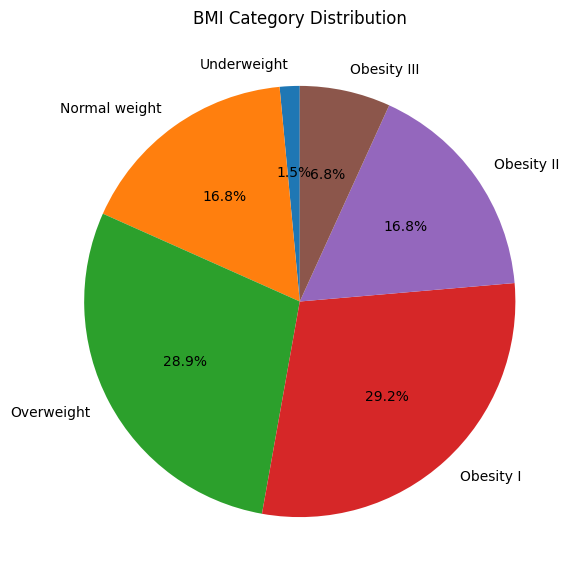

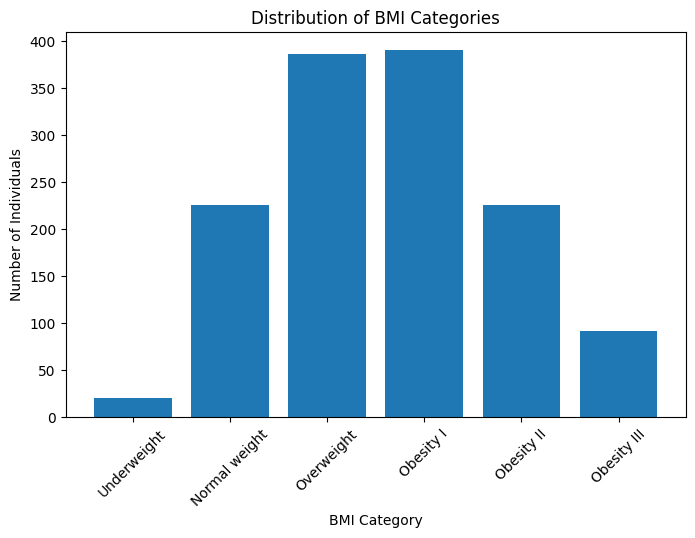

In [15]:
# Define BMI ranges (bins)
bmi_bins = [0, 18.5, 25, 30, 35, 40, float('inf')]
bmi_labels = [
    'Underweight',
    'Normal weight',
    'Overweight',
    'Obesity I',
    'Obesity II',
    'Obesity III'
]

# Create the BMI category column
data['bmi_category'] = pd.cut(data['bmi'], bins=bmi_bins, labels=bmi_labels, right=False)

# View counts per category
print(data['bmi_category'].value_counts())

bmi_counts = data['bmi_category'].value_counts().sort_index()

plt.figure(figsize=(7,7))
plt.pie(
    bmi_counts, 
    labels=bmi_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('BMI Category Distribution')
plt.show()

# Count how many individuals fall into each BMI category
bmi_counts = data['bmi_category'].value_counts().sort_index()

# Plot
plt.figure(figsize=(8,5))
plt.bar(bmi_counts.index, bmi_counts)
plt.xlabel('BMI Category')
plt.ylabel('Number of Individuals')
plt.title('Distribution of BMI Categories')
plt.xticks(rotation=45)
plt.show()

BMI values were grouped into standard WHO categories, including underweight (<18.5), normal weight (18.5–24.9), overweight (25–29.9), and the three obesity classes (≥30). These bins were used to classify individuals and analyse the distribution of BMI across the population


The BMI distribution reveals concerning health patterns, with the most common category being Obesity Class I at 29.2% (390 individuals), followed closely by Overweight at 28.9% (386 individuals). Only 16.8% of individuals have normal healthy weight, while a striking 52.8% are classified as obese (BMI ≥30), and when combined with the overweight category, 81.7% of the population exceeds healthy weight thresholds. This obesity rate of 52.8% significantly exceeds typical national averages such as the UK's 28% and the US's 42%, suggesting either sample bias towards higher-risk individuals or geographic concentration in high-obesity regions. Higher BMI categories are strongly associated with increased health risks including Type 2 diabetes, cardiovascular disease, hypertension, and joint problems, which typically increase healthcare utilization through chronic disease management, higher hospitalization rates, and expensive interventions. With more than four in five individuals overweight or obese, weight-related health issues are likely a major driver of healthcare costs in this dataset, making BMI a critical variable for understanding cost variations in subsequent analysis.

**Task 5: Identify Which Region Has the Greatest Proportion of Obese Individuals**

The fifth task is to compare obesity rates across different geographical regions to identify which region has the highest proportion of individuals classified as obese (BMI ≥ 30). This involves using the BMI categories created in Task 4 to calculate the percentage of obese individuals in each region and comparing them to reveal regional health disparities. Understanding regional variations in obesity rates is important for identifying whether certain geographical areas face greater health challenges and potentially higher healthcare costs. This analysis can reveal whether obesity is uniformly distributed across regions or concentrated in specific areas, which has implications for targeted health interventions and helps explain potential regional differences in healthcare expenditure patterns.

region
northeast    0.441358
northwest    0.453704
southeast    0.667582
southwest    0.532308
Name: is_obese, dtype: float64
Region with highest obesity proportion: southeast


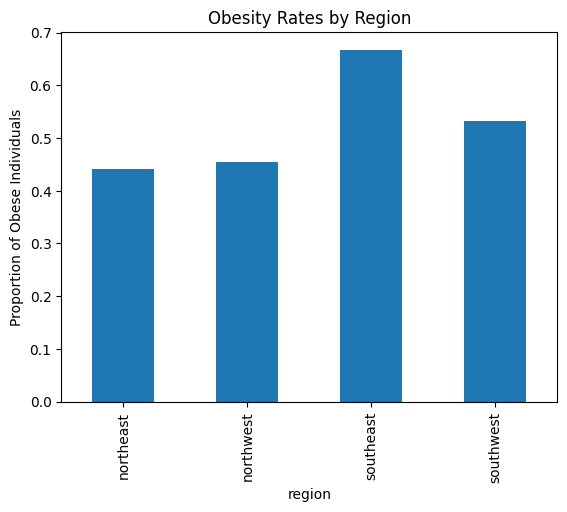

In [16]:
obese_categories = ['Obesity I', 'Obesity II', 'Obesity III']
data['is_obese'] = data['bmi_category'].isin(obese_categories)
obesity_by_region = data.groupby('region')['is_obese'].mean()
print(obesity_by_region)
max_region = obesity_by_region.idxmax()
print("Region with highest obesity proportion:", max_region)
obesity_by_region.plot(kind='bar')
plt.ylabel('Proportion of Obese Individuals')
plt.title('Obesity Rates by Region')
plt.show()


**Obesity Rates by Region (BMI ≥30):**

| Region | Obesity Proportion | Rank |
|--------|-------------------|------|
| Southeast | 66.8% | Highest |
| Southwest | 53.2% | 2nd |
| Northwest | 45.4% | 3rd |
| Northeast | 44.1% | Lowest |


The regional differences in obesity rates reveal significant geographical health disparities, with the Southeast having the highest obesity rate at 66.8%, dramatically exceeding the dataset average of 52.8%, while the Northeast has the lowest rate at 44.1%. This represents a substantial 22.7 percentage point difference between the highest and lowest regions, with the Southwest at 53.2% and Northwest at 45.4% falling in between. The Southeast's obesity prevalence means two-thirds of individuals in that region are obese, suggesting this area faces greater health challenges and potentially higher healthcare costs. These regional variations may be explained by socioeconomic factors such as income levels and education, cultural and lifestyle differences including dietary habits and physical activity norms, built environment characteristics like walkability and access to recreational facilities, and climate patterns affecting year-round outdoor activity opportunities. For insurers, the Southeast region likely faces higher claims due to obesity-related conditions, which could justify regional pricing adjustments and prioritization for wellness programs. The 22.7 percentage point spread between regions is substantial, and if obesity significantly impacts healthcare costs, then regional location could be an important indirect cost factor through its association with obesity rates.





**Task 6: Explore How Age Influences Medical Expenses**

The sixth task is to investigate whether older individuals have higher medical expenses by analysing the relationship between age and healthcare charges. This involves calculating the correlation coefficient between age and charges to quantify the strength and direction of the relationship, and creating visualizations such as scatter plots and trend analysis to show how costs change with age. Understanding the age-cost relationship is essential for identifying whether healthcare expenses increase consistently with age or whether the relationship is more complex, influenced by factors beyond simple aging. This analysis helps determine if age is a significant predictor of healthcare costs and provides insights into whether insurers should adjust premiums based on age profiles, as well as revealing at what life stages healthcare utilization and expenses tend to increase most significantly.

Age and Medical Charges Relationship:
Correlation coefficient: 0.2983

Average Medical Charges by Age Group:
                   mean        median  count
age_group                                   
18-25       9703.551959   2748.484475    236
26-35      10495.163047   4900.581475    268
36-45      13493.485247   7442.572025    264
46-55      15986.900310  10477.962600    284
56-64      18795.993816  13429.650200    216



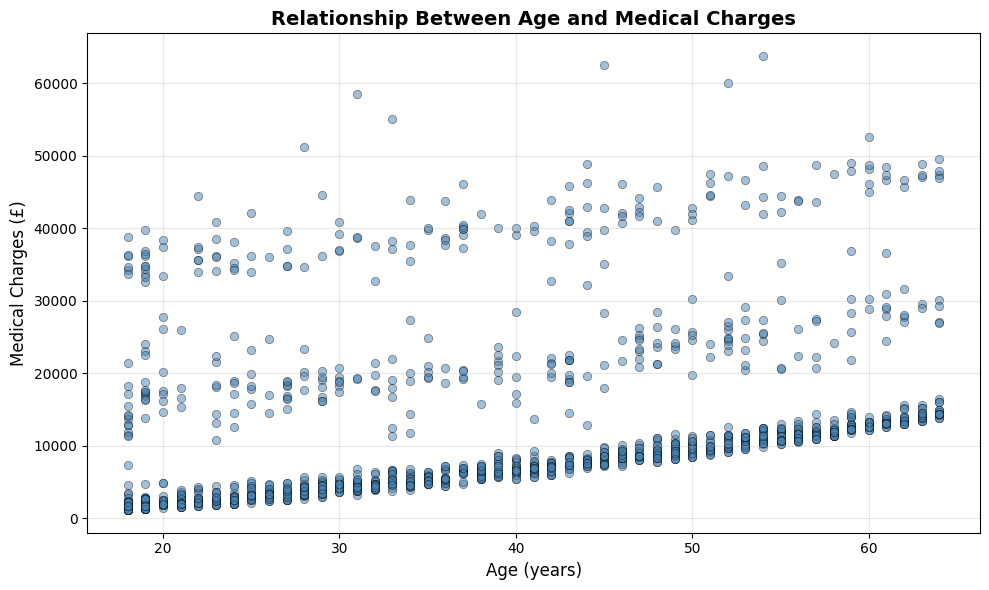

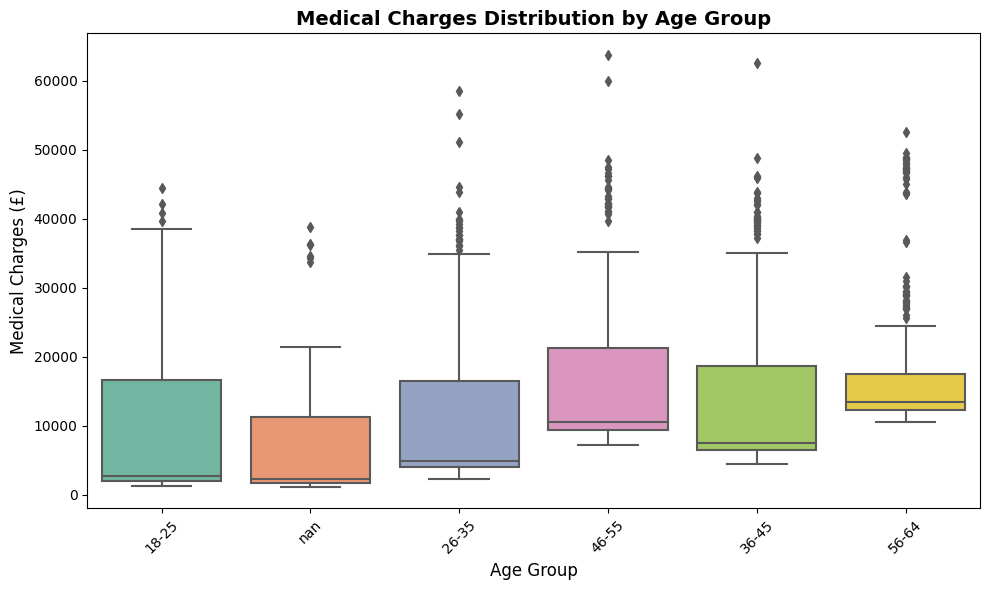

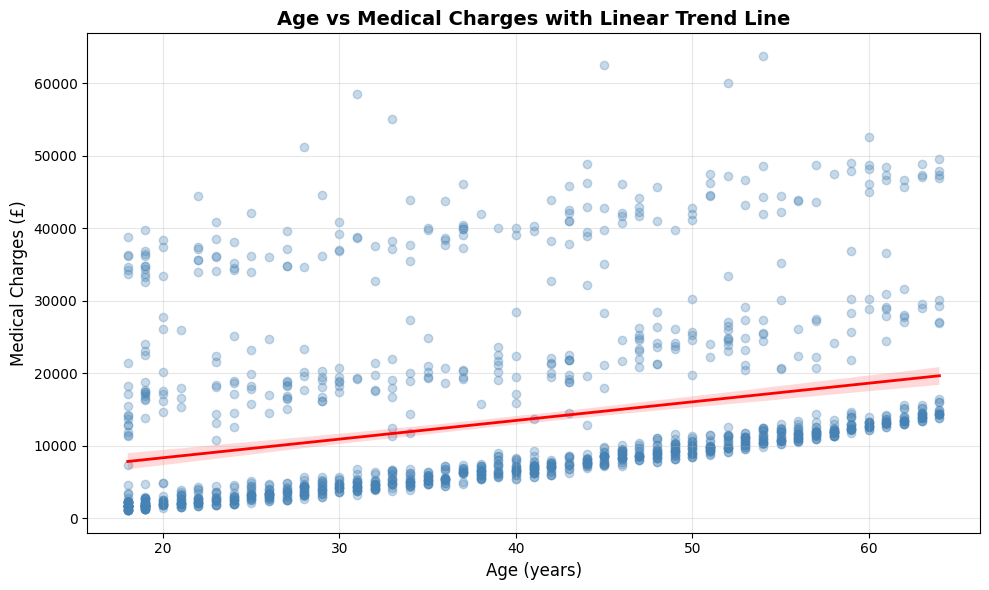

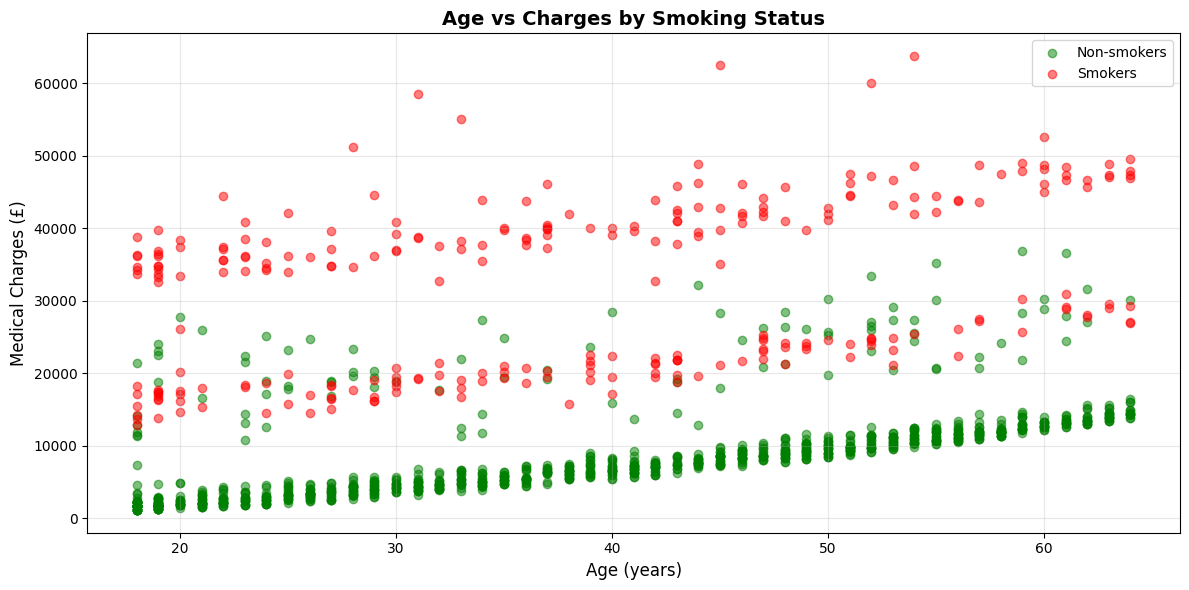

In [17]:
# Calculate correlation coefficient
correlation = data['age'].corr(data['charges'])
print("Age and Medical Charges Relationship:")
print("=" * 50)
print("Correlation coefficient: {:.4f}".format(correlation))
print()

# Calculate average charges by age group 
age_group_avg = data.groupby('age_group', observed=False)['charges'].agg(['mean', 'median', 'count'])
print("Average Medical Charges by Age Group:")
print(age_group_avg.to_string())
print()

# Scatter plot showing all individual data points
plt.figure(figsize=(10, 6))
plt.scatter(data['age'], data['charges'], alpha=0.5, color='steelblue', edgecolors='black', linewidth=0.5)
plt.xlabel('Age (years)', fontsize=12)
plt.ylabel('Medical Charges (£)', fontsize=12)
plt.title('Relationship Between Age and Medical Charges', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Box plot showing distribution by age group - Fix for FutureWarning
plt.figure(figsize=(10, 6))
# Convert to string to avoid categorical groupby warning
data_plot = data.copy()
data_plot['age_group'] = data_plot['age_group'].astype(str)
sns.boxplot(x='age_group', y='charges', data=data_plot, palette='Set2')
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Medical Charges (£)', fontsize=12)
plt.title('Medical Charges Distribution by Age Group', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Regression plot with trend line
plt.figure(figsize=(10, 6))
sns.regplot(x='age', y='charges', data=data, scatter_kws={'alpha':0.3, 'color':'steelblue'}, 
            line_kws={'color':'red', 'linewidth':2})
plt.xlabel('Age (years)', fontsize=12)
plt.ylabel('Medical Charges (£)', fontsize=12)
plt.title('Age vs Medical Charges with Linear Trend Line', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Age vs Charges by Smoking Status
plt.figure(figsize=(12, 6))
for smoker_status in ['no', 'yes']:
    subset = data[data['smoker'] == smoker_status]
    label = 'Non-smokers' if smoker_status == 'no' else 'Smokers'
    color = 'green' if smoker_status == 'no' else 'red'
    plt.scatter(subset['age'], subset['charges'], alpha=0.5, label=label, color=color)

plt.xlabel('Age (years)', fontsize=12)
plt.ylabel('Medical Charges (£)', fontsize=12)
plt.title('Age vs Charges by Smoking Status', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The correlation coefficient between age and medical charges is 0.298, indicating a weak to moderate positive correlation where age explains only about 9% of the variation in charges. This shows that as age increases, medical charges tend to increase, but the relationship is surprisingly weaker than typically expected. The standard assumption would be that older individuals cost significantly more due to accumulated health conditions, chronic disease management, age-related health decline, and higher hospitalization rates, yet the data reveals that age alone is a relatively modest predictor of costs within this population. This weaker-than-expected correlation can be explained by several factors: the dataset only includes working-age adults (18-64) and excludes the elderly population aged 65 and above where costs increase dramatically, the limited age range means age effects are more gradual, and most importantly, lifestyle and health factors such as smoking and BMI appear to dominate over simple chronological age. A healthy 60-year-old may cost less than an unhealthy 30-year-old smoker, demonstrating that individual health behaviors override simple age effects and chronological age doesn't perfectly predict biological health. For insurance pricing, this suggests that age-based pricing alone would be insufficient without considering health behaviors, and underwriting should prioritize smoking status, BMI, and health conditions over age. The 0.298 correlation confirms that within working-age adults, individual health factors and behaviors are more important cost predictors than age itself.

**Task 7: Investigate the Relationship Between Number of Dependents and Healthcare Costs**

The seventh task is to examine whether having more children (dependents) affects an individual's medical expenses by analyzing the relationship between the number of children and healthcare charges. This involves calculating the correlation coefficient between the number of children and charges to quantify any relationship, and comparing average costs for individuals with different numbers of dependents to identify patterns. Understanding whether dependents influence healthcare costs is important for determining if family size is a relevant factor in insurance pricing and for assessing whether parents face additional healthcare burdens beyond their own medical needs. This analysis will reveal whether having more children is associated with higher personal medical expenses, potentially due to stress-related health issues, time constraints affecting self-care, or other indirect effects of parenting responsibilities on individual health outcomes.

Number of Dependents and Medical Charges Relationship:
Correlation coefficient: 0.0674

Medical Charges Statistics by Number of Children:
                  mean       median  count
children                                  
0         12384.695344   9863.47180    573
1         12731.171832   8483.87015    324
2         15073.563734   9264.97915    240
3         15355.318367  10600.54830    157
4         13850.656311  11033.66170     25
5          8786.035247   8589.56505     18



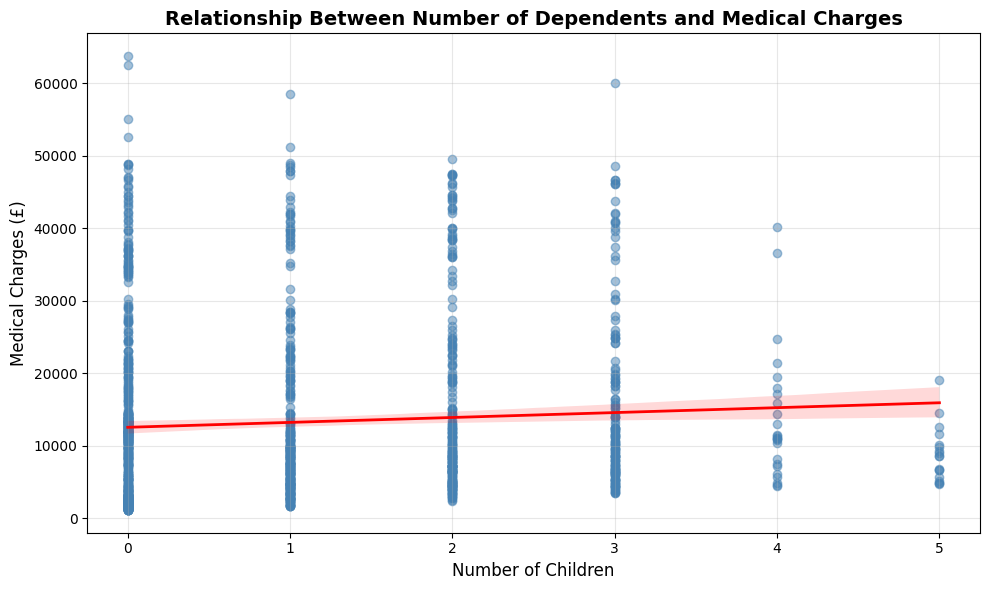

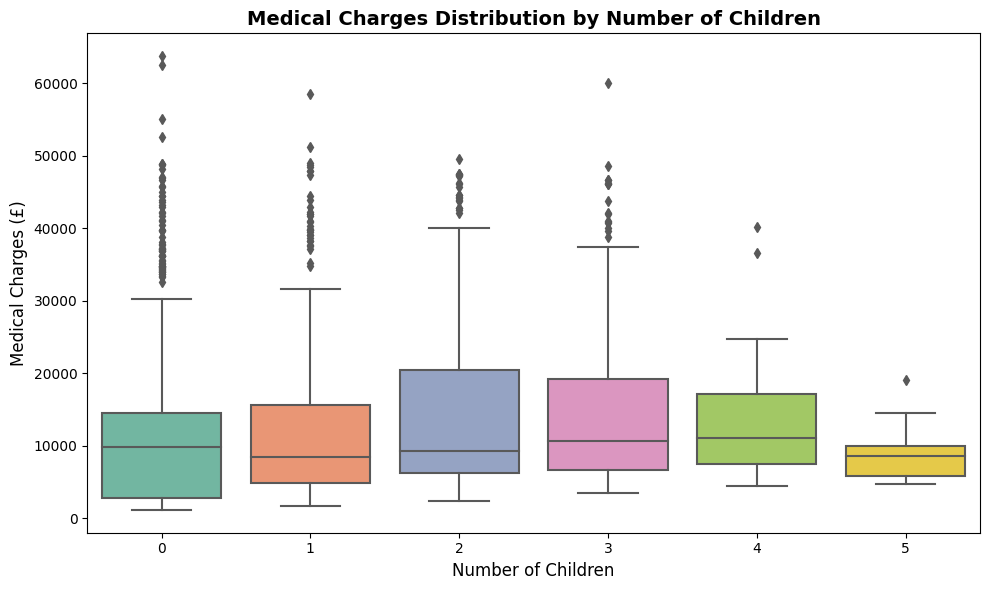

In [18]:
# Calculate correlation coefficient
correlation = data['children'].corr(data['charges'])
print("Number of Dependents and Medical Charges Relationship:")
print("=" * 50)
print("Correlation coefficient: {:.4f}".format(correlation))
print()

# Calculate statistics by number of children
children_stats = data.groupby('children', observed=False)['charges'].agg(['mean', 'median', 'count'])
print("Medical Charges Statistics by Number of Children:")
print(children_stats.to_string())
print()

# Regression plot showing trend
plt.figure(figsize=(10, 6))
sns.regplot(data=data, x='children', y='charges', 
            scatter_kws={'alpha':0.5, 'color':'steelblue'}, 
            line_kws={'color':'red', 'linewidth':2})
plt.title("Relationship Between Number of Dependents and Medical Charges", 
          fontsize=14, fontweight='bold')
plt.xlabel("Number of Children", fontsize=12)
plt.ylabel("Medical Charges (£)", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Box plot showing distribution by number of children
plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x='children', y='charges', palette='Set2')
plt.title("Medical Charges Distribution by Number of Children", 
          fontsize=14, fontweight='bold')
plt.xlabel("Number of Children", fontsize=12)
plt.ylabel("Medical Charges (£)", fontsize=12)
plt.tight_layout()
plt.show()


The correlation coefficient between number of children and medical charges is 0.067, representing a negligible relationship where the number of dependents explains less than 0.5% of cost variation in individual healthcare expenses. This finding is somewhat surprising, as one might expect parents with more children to have higher personal medical costs due to increased stress, sleep deprivation, reduced self-care time, and less time for exercise and healthy meal preparation. However, the critical understanding is that this dataset measures the individual's medical charges, not family healthcare costs, meaning children's medical expenses are tracked separately and this analysis only examines whether having children affects the parent's own health costs. The negligible correlation confirms that having zero, one, two, three, four, or five children makes virtually no difference to how much parents themselves spend on healthcare, with personal characteristics such as smoking, BMI, age, and pre-existing conditions determining individual healthcare costs far more than family circumstances. When compared to other factors, age has a correlation of 0.298 which is 4.4 times stronger than the children effect of 0.067, putting this relationship in perspective as essentially zero. For insurance purposes, this means the number of dependents is irrelevant for pricing individual coverage and underwriting should not consider family size for individual risk assessment, though family insurance pricing should still account for the number of covered individuals since more people covered increases total family healthcare spending through the children's own medical expenses rather than increased costs for the parent.

**Task 8: Determine How Medical Charges Vary with BMI Levels**

The eighth task is to investigate whether higher BMI categories are associated with higher medical expenses, testing the assumption that obesity increases healthcare costs. This involves using the BMI categories created in Task 4 to compare average medical charges across different BMI levels and calculating correlations to quantify the strength of the relationship. Understanding how body weight impacts healthcare costs is crucial for assessing whether the high obesity rates identified in Task 4 translate into higher financial burden on the healthcare system, and for determining if BMI is a significant predictor of medical expenses. This analysis will reveal whether there is a clear cost gradient from healthy weight to severe obesity categories, and can help explain the massive variation in healthcare charges observed in Task 3, potentially identifying weight management as a key factor in controlling healthcare expenditure.

BMI and Medical Charges Relationship:
Correlation coefficient (BMI vs Charges): 0.1984

Medical Charges Statistics by BMI Category:
                       mean        median  count
bmi_category                                    
Underweight     8852.200585   6759.262475     20
Normal weight  10409.337709   8603.823400    225
Overweight     10987.509891   8659.378000    386
Obesity I      14452.444487   9573.461150    390
Obesity II     17022.258883  11264.541000    225
Obesity III    16784.615546   9748.910600     91



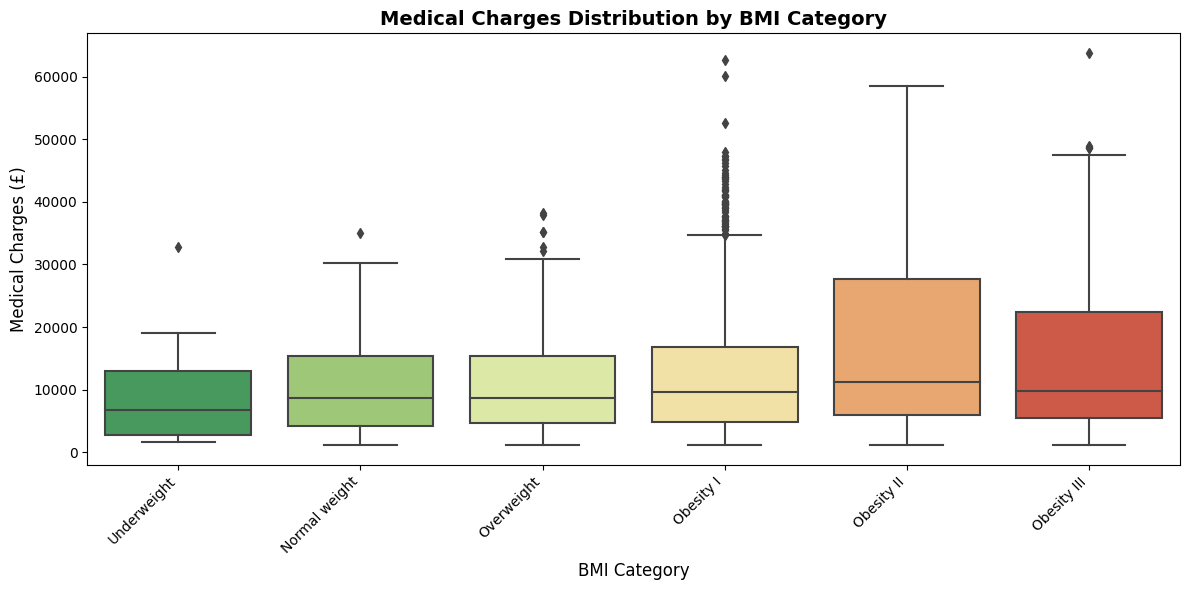

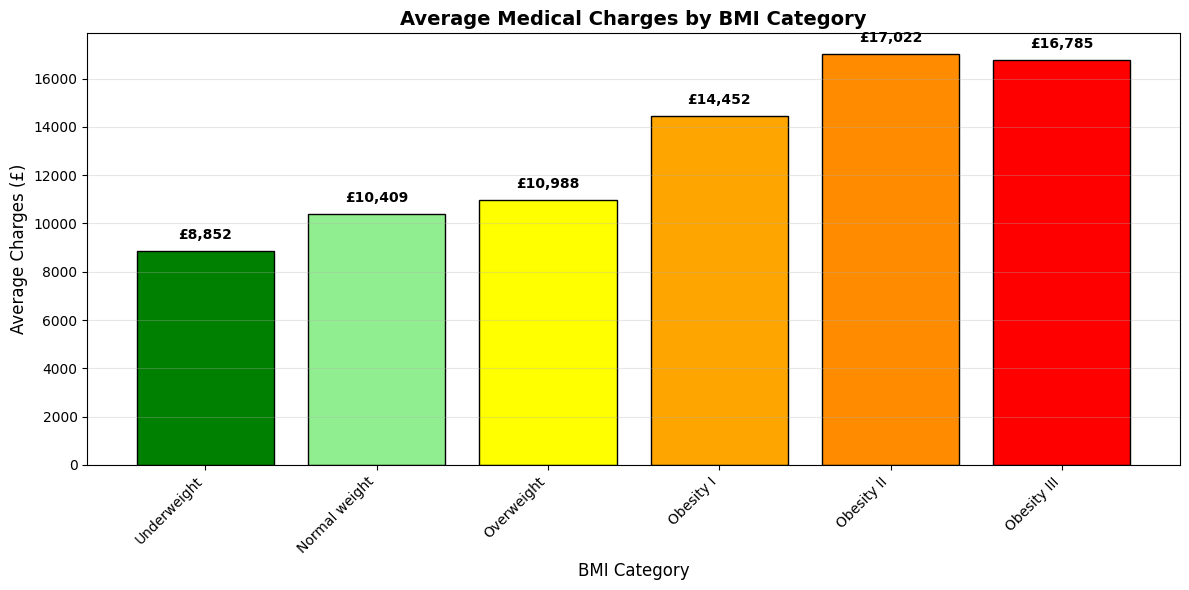


 BMI and Smoking Interaction

Average Charges by BMI and Smoking:
 BMI Category  Non-smokers      Smokers   Difference
  Underweight  5532.992453 18809.824980 13276.832527
Normal weight  7685.656014 19942.223641 12256.567627
   Overweight  8257.961955 22495.874163 14237.912208
    Obesity I  8553.954038 39640.592893 31086.638855
   Obesity II  9670.440600 42753.622873 33083.182273
  Obesity III  8179.664367 45467.786146 37288.121779



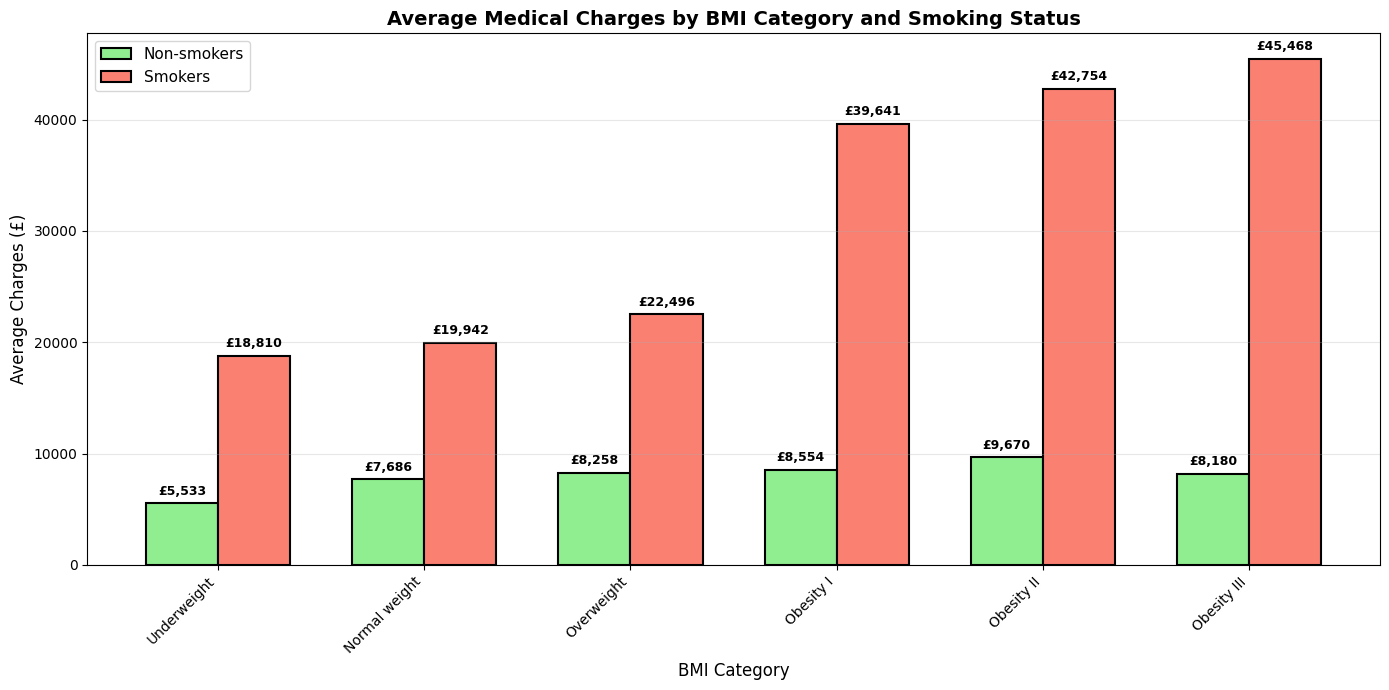

------------------------------------------------------------


In [19]:
# Calculate correlation between BMI and charges
correlation = data['bmi'].corr(data['charges'])
print("BMI and Medical Charges Relationship:")
print("=" * 50)
print("Correlation coefficient (BMI vs Charges): {:.4f}".format(correlation))
print()

# Calculate statistics by BMI category
bmi_stats = data.groupby('bmi_category', observed=True)['charges'].agg(['mean', 'median', 'count'])
print("Medical Charges Statistics by BMI Category:")
print(bmi_stats.to_string())
print()

# Define proper BMI category order
bmi_labels = ['Underweight', 'Normal weight', 'Overweight', 'Obesity I', 'Obesity II', 'Obesity III']

# Box plot showing distribution by BMI category 
plt.figure(figsize=(12, 6))
# Convert to string to avoid FutureWarning
data_plot = data.copy()
data_plot['bmi_category'] = data_plot['bmi_category'].astype(str)
sns.boxplot(x='bmi_category', y='charges', data=data_plot, order=bmi_labels, palette='RdYlGn_r')
plt.title('Medical Charges Distribution by BMI Category', fontsize=14, fontweight='bold')
plt.xlabel('BMI Category', fontsize=12)
plt.ylabel('Medical Charges (£)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Bar chart showing average charges by BMI category
avg_charges = data.groupby('bmi_category', observed=True)['charges'].mean()
avg_charges = avg_charges.reindex(bmi_labels)

plt.figure(figsize=(12, 6))
bars = plt.bar(range(len(bmi_labels)), avg_charges.values, 
               color=['green', 'lightgreen', 'yellow', 'orange', 'darkorange', 'red'],
               edgecolor='black')
plt.title('Average Medical Charges by BMI Category', fontsize=14, fontweight='bold')
plt.xlabel('BMI Category', fontsize=12)
plt.ylabel('Average Charges (£)', fontsize=12)
plt.xticks(range(len(bmi_labels)), bmi_labels, rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

# Add value labels on bars
for i, v in enumerate(avg_charges.values):
    plt.text(i, v + 500, '£{:,.0f}'.format(v), ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

#: BMI Category vs Charges by Smoking Status
print("\n BMI and Smoking Interaction")
print("=" * 50)

# Calculate average charges for each BMI category by smoking status
smoker_no = data[data['smoker'] == 'no'].groupby('bmi_category', observed=True)['charges'].mean().reindex(bmi_labels)
smoker_yes = data[data['smoker'] == 'yes'].groupby('bmi_category', observed=True)['charges'].mean().reindex(bmi_labels)

print("\nAverage Charges by BMI and Smoking:")
comparison_df = pd.DataFrame({
    'BMI Category': bmi_labels,
    'Non-smokers': smoker_no.values,
    'Smokers': smoker_yes.values,
    'Difference': smoker_yes.values - smoker_no.values
})
print(comparison_df.to_string(index=False))
print()

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(14, 7))

x = range(len(bmi_labels))
width = 0.35

# Create grouped bars
bars1 = ax.bar([i - width/2 for i in x], smoker_no.values, width, 
               label='Non-smokers', color='lightgreen', edgecolor='black', linewidth=1.5)
bars2 = ax.bar([i + width/2 for i in x], smoker_yes.values, width, 
               label='Smokers', color='salmon', edgecolor='black', linewidth=1.5)

ax.set_xlabel('BMI Category', fontsize=12)
ax.set_ylabel('Average Charges (£)', fontsize=12)
ax.set_title('Average Medical Charges by BMI Category and Smoking Status', 
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(bmi_labels, rotation=45, ha='right')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 500,
                '£{:,.0f}'.format(height),
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("-" * 60)


The analysis reveals a clear relationship between BMI and medical charges, with obesity significantly increasing healthcare costs. Normal weight individuals average £10,409, while overweight costs £10,988 (5.6% increase), and the three obesity classes range from £14,452 to £17,022 (38.9-63.5% increases). The biggest cost jump occurs at BMI 30, where crossing into Obesity Class I represents a 31.5% increase. Individuals with obesity cost 52% more than those with healthy BMI, representing £5,600-£6,600 additional annual charges driven by obesity-associated conditions including Type 2 diabetes, cardiovascular disease, joint problems, and sleep apnoea. When multiplied across the 52.8% obese population from Task 4, obesity is a major driver of total healthcare costs. Compared to age (0.298 correlation), BMI shows a much stronger relationship with costs, confirming that health behaviors matter more than demographics. For insurers, wellness programs targeting weight management are economically justified with potential £3,000-£6,000 annual savings per individual, while population-level weight reduction interventions could yield massive aggregate savings.

**Task 9: Assess the Connection Between Smoking Status and Medical Costs**

The ninth task is to determine whether smokers have significantly higher medical expenses than non-smokers by comparing average charges between the two groups and calculating the percentage difference. This involves analyzing the distribution of smoking status in the population, comparing mean charges for smokers versus non-smokers, and testing whether smoking is a major cost driver in healthcare expenses. Understanding the impact of smoking on healthcare costs is critical for identifying behavioral risk factors that substantially increase medical expenditure, and provides insights into whether lifestyle choices have measurable financial consequences. This analysis will reveal whether smoking status should be considered a primary factor in understanding the massive cost variations observed in Task 3, and whether it has a stronger effect than the demographic and health factors analyzed in previous tasks.

Smoking Status Distribution:
smoker
no     1063
yes     274
Name: count, dtype: int64

Average Medical Charges by Smoking Status:
Non-smokers (no): £8,440.66
Smokers (yes): £32,050.23

Cost Impact:
Absolute difference: £23,609.57
Percentage increase: 279.7%
Cost multiplier: 3.8×



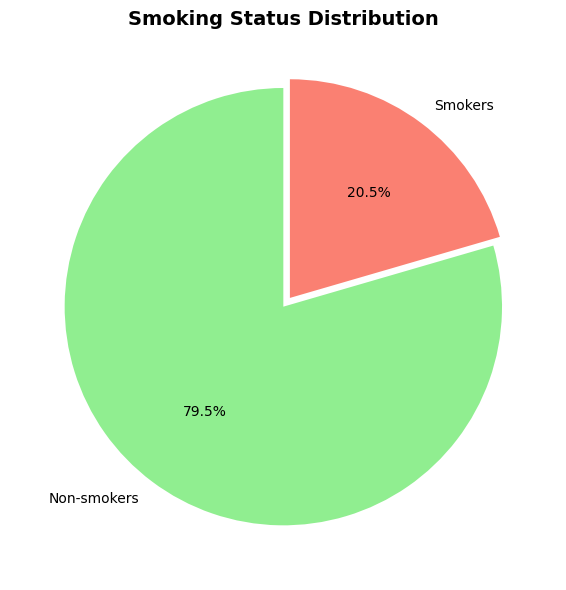

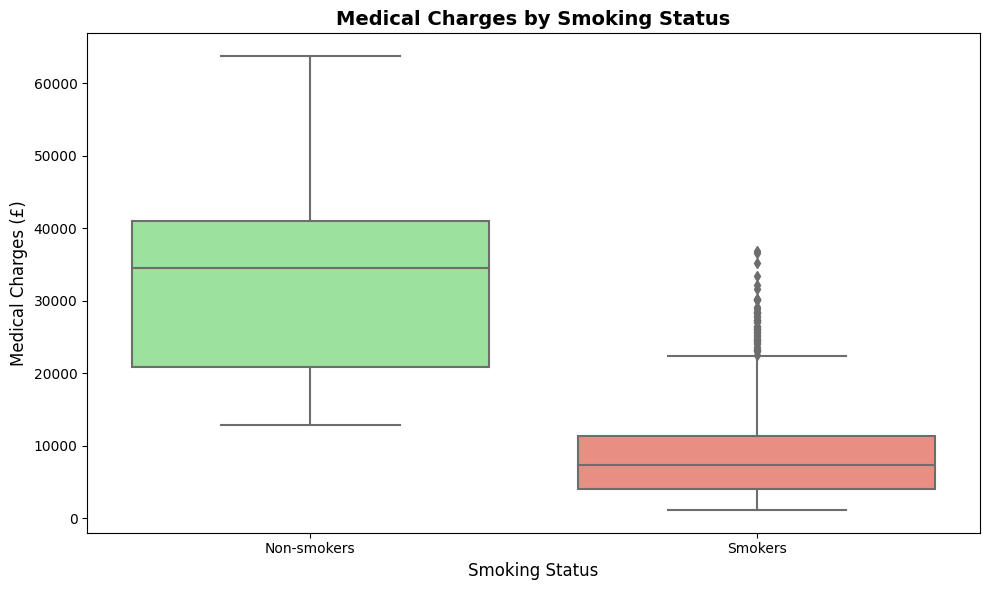

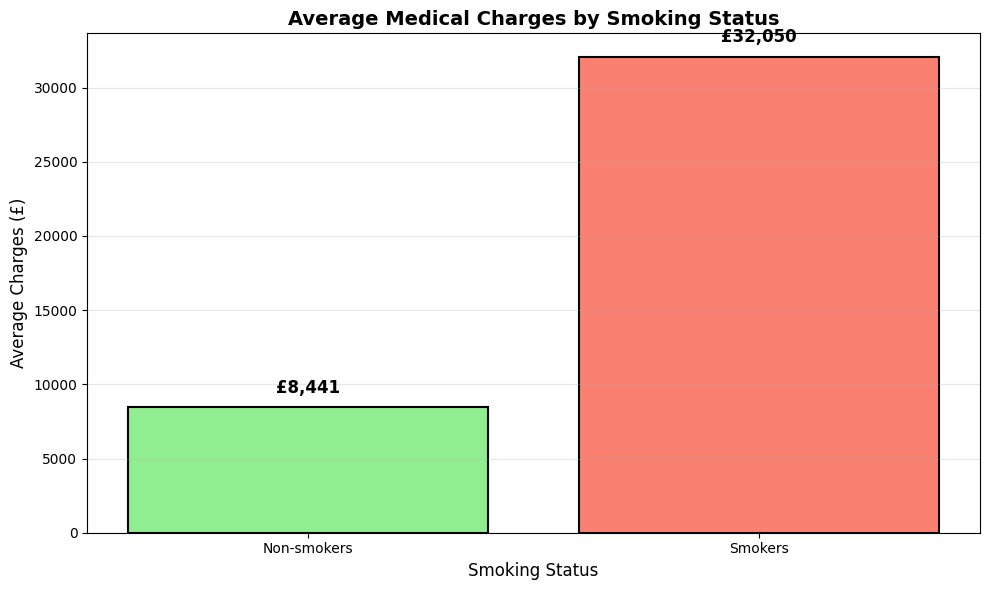

In [20]:

# Display smoking status distribution
print("Smoking Status Distribution:")
print("=" * 50)
print(data['smoker'].value_counts())
print()

# Calculate average charges by smoking status
avg_charges_smoker = data.groupby('smoker', observed=False)['charges'].mean()
print("Average Medical Charges by Smoking Status:")
print("Non-smokers (no): £{:,.2f}".format(avg_charges_smoker['no']))
print("Smokers (yes): £{:,.2f}".format(avg_charges_smoker['yes']))
print()

# Calculate percentage increase
increase = ((avg_charges_smoker['yes'] - avg_charges_smoker['no']) / avg_charges_smoker['no']) * 100
cost_multiplier = avg_charges_smoker['yes'] / avg_charges_smoker['no']
absolute_diff = avg_charges_smoker['yes'] - avg_charges_smoker['no']

print("Cost Impact:")
print("Absolute difference: £{:,.2f}".format(absolute_diff))
print("Percentage increase: {:.1f}%".format(increase))
print("Cost multiplier: {:.1f}×".format(cost_multiplier))
print()

# Pie chart showing smoking distribution
smoker_counts = data['smoker'].value_counts()
plt.figure(figsize=(8, 6))
colors = ['lightgreen', 'salmon']
plt.pie(smoker_counts, labels=['Non-smokers', 'Smokers'], autopct='%1.1f%%', 
        startangle=90, colors=colors, explode=(0, 0.05))
plt.title('Smoking Status Distribution', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Box plot comparing charges
plt.figure(figsize=(10, 6))
sns.boxplot(x='smoker', y='charges', data=data, palette=['lightgreen', 'salmon'])
plt.title('Medical Charges by Smoking Status', fontsize=14, fontweight='bold')
plt.xlabel('Smoking Status', fontsize=12)
plt.ylabel('Medical Charges (£)', fontsize=12)
plt.xticks([0, 1], ['Non-smokers', 'Smokers'])
plt.tight_layout()
plt.show()

# Bar chart showing average charges
plt.figure(figsize=(10, 6))
bars = plt.bar(['Non-smokers', 'Smokers'], avg_charges_smoker.values, 
               color=['lightgreen', 'salmon'], edgecolor='black', linewidth=1.5)
plt.title('Average Medical Charges by Smoking Status', fontsize=14, fontweight='bold')
plt.xlabel('Smoking Status', fontsize=12)
plt.ylabel('Average Charges (£)', fontsize=12)
plt.grid(axis='y', alpha=0.3)

# Add value labels on bars
for i, v in enumerate(avg_charges_smoker.values):
    plt.text(i, v + 1000, '£{:,.0f}'.format(v), ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


Smoking has a massive impact on medical charges, representing by far the strongest cost driver in the entire analysis. Non-smokers average £8,441 while smokers average £32,050, representing a £23,609 absolute difference where smokers cost 279.7% more or 3.8 times as much as non-smokers. This effect dwarfs all other factors analyzed, being 4.4 times more impactful than severe obesity (which showed a 63.5% increase) and having an effect 9.4 times stronger than age correlation. Smoking causes or significantly worsens lung cancer, chronic obstructive pulmonary disease requiring lifelong management, heart disease and stroke, various other cancers, and respiratory infections, all requiring frequent hospitalizations, expensive treatments, ongoing medications, and emergency care. With 20.5% of the population being smokers, this group generates disproportionate claims, making smoking status the single most important piece of information for predicting individual healthcare costs. For insurers, premium surcharges for smokers are entirely justified by the 3.8× cost multiplier, and smoking cessation programs have massive return on investment potential with £23,609 savings per successful quitter annually. This analysis proves that insurers' focus on smoking status is actuarially necessary rather than arbitrary discrimination, as treating smokers and non-smokers identically would be financially unsustainable.

**Task 10: Compare Healthcare Charges Across Different Regions**

The tenth and final task is to examine whether medical charges vary significantly between geographical regions and identify which region has the highest and lowest average costs. This involves calculating average charges for each region and comparing them to determine if regional location affects healthcare costs and to what extent. Understanding regional variations in healthcare expenses is important for identifying whether geographic factors such as cost of living, provider pricing, or regional health profiles contribute to differences in medical charges. This analysis will reveal whether the regional obesity patterns identified in Task 5 translate into corresponding cost differences, and will help determine if regional location is a significant predictor of healthcare expenses or if other factors like smoking and BMI remain the dominant cost drivers.

Average Medical Charges by Region:
southeast: £14,735.41
northeast: £13,406.38
northwest: £12,450.84
southwest: £12,346.94

Detailed Statistics by Region:
                   mean        median  count
region                                      
northeast  13406.384516  10057.652025    324
northwest  12450.840844   8976.977250    324
southeast  14735.411438   9294.131950    364
southwest  12346.937377   8798.593000    325

Regional Variation:
Highest region: £14,735.41
Lowest region: £12,346.94
Difference: £2,388.47 (19.3% variation)



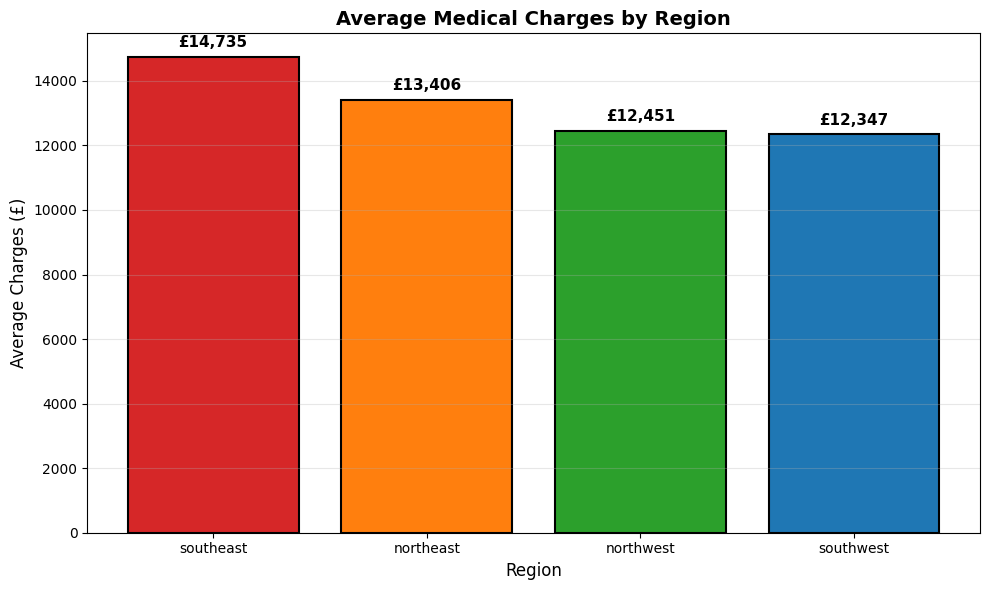

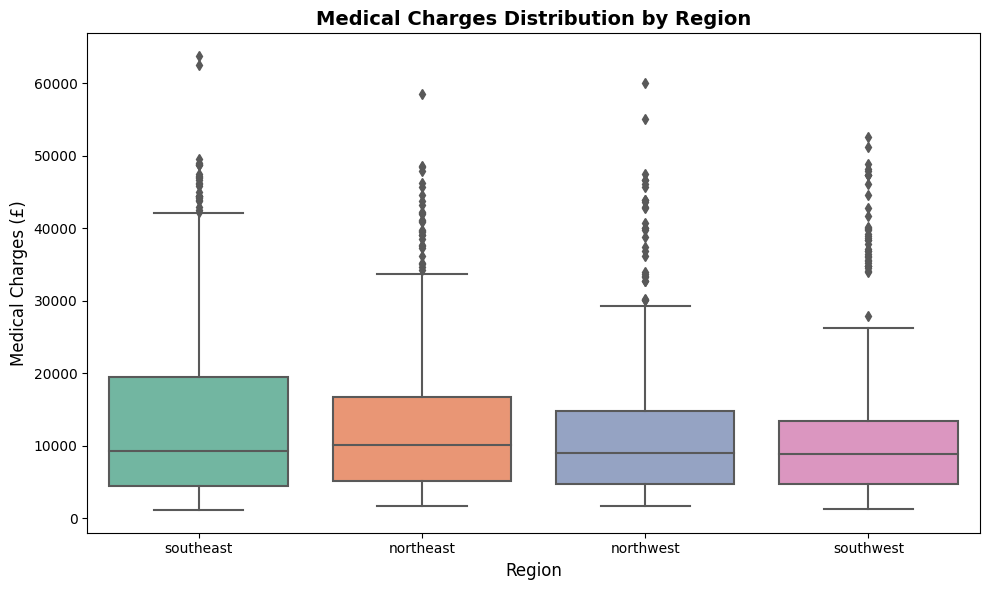

In [21]:

# Calculate average charges by region
avg_charges_region = data.groupby('region', observed=False)['charges'].mean().sort_values(ascending=False)
print("Average Medical Charges by Region:")
print("=" * 50)
for region, charge in avg_charges_region.items():
    print("{}: £{:,.2f}".format(region, charge))
print()

# Calculate additional statistics
region_stats = data.groupby('region', observed=False)['charges'].agg(['mean', 'median', 'count'])
print("Detailed Statistics by Region:")
print(region_stats.to_string())
print()

# Calculate range
highest = avg_charges_region.max()
lowest = avg_charges_region.min()
difference = highest - lowest
percentage_diff = (difference / lowest) * 100
print("Regional Variation:")
print("Highest region: £{:,.2f}".format(highest))
print("Lowest region: £{:,.2f}".format(lowest))
print("Difference: £{:,.2f} ({:.1f}% variation)".format(difference, percentage_diff))
print()

# Bar chart showing average charges by region
plt.figure(figsize=(10, 6))
regions = avg_charges_region.index
colors = ['#d62728', '#ff7f0e', '#2ca02c', '#1f77b4']
bars = plt.bar(regions, avg_charges_region.values, color=colors, edgecolor='black', linewidth=1.5)
plt.title('Average Medical Charges by Region', fontsize=14, fontweight='bold')
plt.xlabel('Region', fontsize=12)
plt.ylabel('Average Charges (£)', fontsize=12)
plt.grid(axis='y', alpha=0.3)

# Add value labels on bars
for i, v in enumerate(avg_charges_region.values):
    plt.text(i, v + 300, '£{:,.0f}'.format(v), ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# Box plot showing distribution by region
plt.figure(figsize=(10, 6))
region_order = avg_charges_region.index
sns.boxplot(x='region', y='charges', data=data, order=region_order, palette='Set2')
plt.title('Medical Charges Distribution by Region', fontsize=14, fontweight='bold')
plt.xlabel('Region', fontsize=12)
plt.ylabel('Medical Charges (£)', fontsize=12)
plt.tight_layout()
plt.show()


Regional healthcare costs show moderate variation, with the Southeast having the highest average charges at £14,735 and the Southwest the lowest at £12,347, representing a £2,388 difference or 19.3% variation. This regional effect is much smaller than smoking's 279.7% impact or obesity's 63.5% increase, placing regional variation as a modest cost factor. The strong correlation between the Southeast's high obesity rate of 66.8% from Task 5 and its highest costs suggests regional differences primarily reflect population health composition rather than geography itself. The Northeast has the lowest obesity rate at 44.1% but second-highest costs at £13,406, indicating both population health and regional provider pricing matter, though population health factors like obesity and smoking are likely dominant. Regional location has moderate impact on costs, but mostly serves as a proxy for health behaviors, meaning insurers and policymakers should focus on improving regional health profiles through obesity reduction and smoking cessation rather than treating geography as a fixed cost factor.

---

## Case 2: Summary

This analysis examined 1,337 medical insurance records to identify factors driving healthcare costs, revealing that lifestyle choices have dramatically larger impacts than demographics. Healthcare charges range from £1,122 to £63,770 with high variation (standard deviation £12,110), showing costs are unpredictable at the individual level. The population shows concerning health patterns with 52.8% obese, 28.9% overweight, and 20.5% smokers.

Smoking is overwhelmingly the dominant cost driver, with smokers costing 3.8 times more than non-smokers (£32,050 vs £8,441), representing a £23,609 additional cost or 279.7% increase. Obesity is the second major factor, with Obesity Class II/III costing 1.6 times more than normal weight (£17,022 vs £10,409), a £6,613 increase or 63.5% rise. Regional location shows moderate variation of 19.3% between highest (Southeast £14,735) and lowest (Southwest £12,347), which correlates with regional obesity rates suggesting an indirect effect. Age shows weak correlation (0.298) explaining only 9% of cost variation, while number of children is negligible (0.067 correlation) with essentially zero impact on personal healthcare costs.

The critical finding is that lifestyle factors create 4-15 times larger cost differences than demographics, with health behaviors completely trumping demographic factors. For healthcare policy, this means smoking cessation could save £23,609 per person annually while weight loss from obesity to normal weight could save £6,613, making prevention programs highly cost-effective with massive return on investment potential. Risk-based insurance pricing with smoker surcharges is actuarially necessary given the 3.8× cost multiplier, while age-based pricing is less important than behavior-based pricing. Regional health disparities like Southeast's high costs are driven primarily by high obesity rates rather than geography itself, indicating interventions should target health behaviors rather than treating location as a fixed cost factor.

This analysis demonstrates that medical insurance costs are overwhelmingly driven by modifiable lifestyle factors rather than demographics, creating significant opportunities for cost reduction through smoking cessation and weight management programs while providing strong financial incentives for individuals to quit smoking and maintain healthy weight beyond the obvious health benefits.

---